In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%pip install -q "recbole==1.2.0" kmeans-pytorch ray

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 94.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 31.6 MB/s eta 0:00:00


In [ ]:
import os
import gc
import json
import hashlib
import importlib.metadata as package_metadata
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd
import torch
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display

if not hasattr(np, 'float_'):
    np.float_ = np.float64
if not hasattr(np, 'float'):
    np.float = float
os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
from recbole.quick_start import load_data_and_model
from recbole.utils import get_trainer
from recbole.data.dataloader import FullSortEvalDataLoader

print({p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']})
if not torch.cuda.is_available():
    raise RuntimeError('Select a Colab GPU runtime before evaluation. Do not reinstall PyTorch blindly.')
print('GPU:', torch.cuda.get_device_name(0))
# Test an actual CUDA operation, not just device detection.
print('CUDA calculation:', (torch.ones(2, device='cuda') * 2).cpu().tolist())
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

{'torch': '2.11.0+cu130', 'recbole': '1.2.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3'}
GPU: NVIDIA A100-SXM4-40GB
CUDA calculation: [2.0, 2.0]


In [ ]:
MY_DRIVE = Path('/content/drive/MyDrive')
PROJECT_OVERRIDE = '/content/drive/MyDrive/Wits_Honours_Project'  # Set only if you know the complete training-project folder
CHECKPOINT_OVERRIDES = {}
DATASET_OVERRIDES = {}  # condition -> exact .inter path, if automatic discovery is ambiguous
UNAVAILABLE_CONDITIONS = {}  # Optional label -> exact absolute checkpoint path
if not MY_DRIVE.is_dir():
    raise FileNotFoundError('Mount the Google Drive account containing your trained models first.')
THRESHOLD = 7
K = 10
EVAL_BATCH_SIZE = 256  # Bound full-sort GPU memory on a T4
MAX_MISSING_USERS_PER_CONDITION = 7
BOOTSTRAP_RESAMPLES = 5000
SEED = 42
NO_HARM_MARGINS = {'hit@10': None, 'ndcg@10': None, 'mrr@10': None}
MARGIN_JUSTIFICATIONS = {'hit@10': '', 'ndcg@10': '', 'mrr@10': ''}

RUNS = {'baseline': {'kind': 'baseline',
              'checkpoint': 'saved/SASRec-Aug-14-2026_09-14-55.pth',
              'recorded': {'hit@10': 0.0843, 'ndcg@10': 0.0437, 'mrr@10': 0.0313}},
 'full_qwen': {'kind': 'full',
               'checkpoint': 'saved/SASRec-Sep-07-2026_06-51-41.pth',
               'recorded': {'hit@10': 0.0447, 'ndcg@10': 0.0238, 'mrr@10': 0.0175}},
 'full_llama': {'kind': 'full',
                'checkpoint': 'saved/SASRec-Sep-07-2026_07-55-05.pth',
                'recorded': {'hit@10': 0.0484, 'ndcg@10': 0.0252, 'mrr@10': 0.0181}},
 'selective_qwen': {'kind': 'selective',
                    'checkpoint': 'saved/SASRec-Sep-28-2026_06-33-55.pth',
                    'recorded': {'hit@10': 0.0736, 'ndcg@10': 0.0376, 'mrr@10': 0.0267}},
 'selective_llama': {'kind': 'selective',
                     'checkpoint': 'saved/SASRec-Sep-28-2026_05-13-51.pth',
                     'recorded': {'hit@10': 0.0747, 'ndcg@10': 0.0389, 'mrr@10': 0.0281}}}
VERIFIED_FULL_QWEN_INTER = None  # Optional independently verified original Qwen .inter path
CONDITIONS = [label for label in RUNS if label != 'baseline']
METRICS = ['ndcg@10', 'hit@10', 'mrr@10']
for metric, margin in NO_HARM_MARGINS.items():
    if margin is not None and (not 0 < margin < 1 or not MARGIN_JUSTIFICATIONS[metric].strip()):
        raise ValueError('Supply a justified absolute margin in (0,1) before analysing results.')

# Locate the actual files before selecting a project folder. The working SASRec
# and BERT4Rec checkpoint names help identify the original training project.
reference_names = {'SASRec-Aug-14-2026_09-14-55.pth', 'BERT4Rec-Aug-16-2026_05-58-15.pth'}
print('Searching this mounted MyDrive for checkpoint files; this may take a moment.')
scan_root = Path(PROJECT_OVERRIDE) if PROJECT_OVERRIDE is not None else MY_DRIVE
if not scan_root.is_dir():
    raise FileNotFoundError(f'Main project folder unavailable: {scan_root}; mount the correct Drive account/check the exact root path.')
inventory = list(scan_root.rglob('*.pth'))
reference_files = [p for p in inventory if p.name in reference_names]
print('SASRec/BERT4Rec reference files:', [str(p) for p in reference_files])
print('SASRec files found:', sum('sasrec' in p.name.lower() for p in inventory))

def locate_checkpoint(label, expected_path, inventory, project_override=None, overrides=None):
    overrides = overrides or {}
    if label in overrides:
        supplied = Path(overrides[label]).expanduser()
        if not supplied.is_file():
            raise FileNotFoundError(f'{label}: supplied checkpoint does not exist: {supplied}')
        return supplied
    if project_override is not None:
        preferred = Path(project_override) / expected_path
        if preferred.is_file():
            return preferred
    matches = [p for p in inventory if p.name == Path(expected_path).name]
    if len(matches) > 1:
        raise ValueError(f'{label}: multiple files with this checkpoint name. Set CHECKPOINT_OVERRIDES[{label!r}] to the intended file: {matches}')
    return matches[0] if matches else None

resolved_paths = {}
for label, run in list(RUNS.items()):
    try:
        found = locate_checkpoint(label, run['checkpoint'], inventory, PROJECT_OVERRIDE, CHECKPOINT_OVERRIDES)
    except (ValueError, FileNotFoundError) as error:
        if label == 'baseline':
            raise
        UNAVAILABLE_CONDITIONS[label] = str(error)
        continue
    if found is None:
        if label == 'baseline':
            raise FileNotFoundError('Original baseline checkpoint not found. A baseline is required; check the mounted account or CHECKPOINT_OVERRIDES.')
        UNAVAILABLE_CONDITIONS[label] = 'Recorded checkpoint file not found: ' + Path(run['checkpoint']).name
    else:
        resolved_paths[label] = found
        print(label, 'FOUND:', found)
RUNS = {label: run for label, run in RUNS.items() if label in resolved_paths}
CONDITIONS = [label for label in RUNS if label != 'baseline']
if not CONDITIONS:
    raise RuntimeError('No augmentation checkpoints available. Check the input paths before evaluating.')

def infer_project(checkpoint_path):
    for parent in checkpoint_path.parents:
        if parent.name.lower() == 'wits_honours_project':
            return parent
        if (parent / 'pipeline').is_dir() and ((parent / 'datasets').is_dir() or (parent / 'Datasets').is_dir()):
            return parent
    raise ValueError('Cannot identify the main project root. Set PROJECT_OVERRIDE explicitly; do not use pipeline/training as the root.')

PROJECT = Path(PROJECT_OVERRIDE) if PROJECT_OVERRIDE is not None else infer_project(resolved_paths['baseline'])
if not PROJECT.is_dir():
    raise FileNotFoundError(f'Actual project folder missing: {PROJECT}')
os.chdir(PROJECT)
for label, path in resolved_paths.items():
    RUNS[label]['checkpoint'] = str(path)  # Absolute paths; no case-sensitive project guess
print('Resolved training project:', PROJECT)

RUN_DIR = PROJECT / 'results/significance/video_games_sasrec_full_and_selective' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
for subfolder in ['preparation', 'per_user', 'analysis', 'figures']:
    (RUN_DIR / subfolder).mkdir(parents=True, exist_ok=False)
print('New output folder:', RUN_DIR)

Searching this mounted MyDrive for checkpoint files; this may take a moment.
SASRec/BERT4Rec reference files: ['/content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Aug-14-2026_09-14-55.pth', '/content/drive/MyDrive/Wits_Honours_Project/saved/BERT4Rec-Aug-16-2026_05-58-15.pth']
SASRec files found: 15
baseline FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Aug-14-2026_09-14-55.pth
full_qwen FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Sep-07-2026_06-51-41.pth
full_llama FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Sep-07-2026_07-55-05.pth
selective_qwen FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Sep-28-2026_06-33-55.pth
selective_llama FOUND: /content/drive/MyDrive/Wits_Honours_Project/saved/SASRec-Sep-28-2026_05-13-51.pth
Resolved training project: /content/drive/MyDrive/Wits_Honours_Project
New output folder: /content/drive/MyDrive/Wits_Honours_Project/results/significance/video_games_sasrec_full_and_selec

In [ ]:
def file_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def fingerprint(tokens):
    return hashlib.sha256(
        json.dumps(
            sorted(map(str, tokens)), ensure_ascii=False
        ).encode()
    ).hexdigest()


# Keep any overrides already provided in the setup cell.
DATASET_OVERRIDES = globals().get('DATASET_OVERRIDES', {})
UNAVAILABLE_CONDITIONS = globals().get('UNAVAILABLE_CONDITIONS', {})
VERIFIED_FULL_QWEN_INTER = globals().get(
    'VERIFIED_FULL_QWEN_INTER', None
)
EVAL_BATCH_SIZE = globals().get('EVAL_BATCH_SIZE', 256)


def resolve_dataset_path(saved_path, dataset_name, project, label):
    filename = str(dataset_name) + '.inter'

    if label in DATASET_OVERRIDES:
        supplied = Path(DATASET_OVERRIDES[label])
        if not supplied.is_file() or supplied.name != filename:
            raise FileNotFoundError(
                f'{label}: dataset override must be an existing '
                f'{filename} file.'
            )
        return supplied

    direct = Path(saved_path) / filename
    if direct.is_file():
        return direct

    matches = sorted(Path(project).rglob(filename))

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1:
        hashes = {file_hash(path) for path in matches}
        if len(hashes) == 1:
            print(
                label, 'identical dataset copies found; using',
                matches[0]
            )
            return matches[0]

    raise FileNotFoundError(
        f'{label}: expected {filename}; found {len(matches)} '
        'missing or ambiguous candidates in the main project. '
        'Set DATASET_OVERRIDES explicitly.'
    )


evaluation_checkpoint_paths = {}
TEMP_CHECKPOINT_DIR = Path('/content/sasrec_evaluation_path_copies')
TEMP_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

saved_configs = {}
input_paths = {}
provenance = {}
config_rows = []

fields = [
    'model', 'dataset', 'seed', 'hidden_size', 'inner_size',
    'n_layers', 'n_heads', 'hidden_dropout_prob',
    'attn_dropout_prob', 'MAX_ITEM_LIST_LENGTH', 'loss_type',
    'learning_rate', 'train_batch_size', 'epochs',
    'stopping_step', 'eval_args', 'topk', 'embedding_size',
    'num_layers', 'dropout_prob', 'mask_ratio'
]

for label, run in RUNS.items():
    checkpoint_path = PROJECT / run['checkpoint']

    # Only load your own trusted training checkpoints.
    checkpoint = torch.load(
        checkpoint_path,
        map_location='cpu',
        weights_only=False
    )

    config = checkpoint['config']
    settings = (
        config.final_config_dict
        if hasattr(config, 'final_config_dict')
        else config
    )

    saved_configs[label] = {
        field: settings.get(field) for field in fields
    }

    saved_topk = settings.get('topk', [])
    if isinstance(saved_topk, (int, np.integer)):
        saved_topk = [int(saved_topk)]

    if settings.get('model') != 'SASRec' or K not in saved_topk:
        if label == 'baseline':
            raise ValueError(
                'Baseline checkpoint has the wrong model or saved top-K.'
            )
        UNAVAILABLE_CONDITIONS[label] = (
            'Checkpoint model/top-K does not match this notebook.'
        )
        del checkpoint
        continue

    original_saved_data_path = str(settings['data_path'])

    try:
        inter_path = resolve_dataset_path(
            original_saved_data_path,
            settings['dataset'],
            PROJECT,
            label
        )
    except FileNotFoundError as error:
        if label == 'baseline':
            raise
        UNAVAILABLE_CONDITIONS[label] = str(error)
        del checkpoint
        continue

    checkpoint_hash = file_hash(checkpoint_path)
    interaction_hash = file_hash(inter_path)

    # Change only a temporary evaluation copy.
    # The original saved checkpoint remains untouched.
    settings['data_path'] = str(inter_path.parent)
    settings['eval_batch_size'] = EVAL_BATCH_SIZE

    temporary_path = TEMP_CHECKPOINT_DIR / (
        f'{label}_{checkpoint_hash[:12]}'
        f'_batch{EVAL_BATCH_SIZE}.pth'
    )
    torch.save(checkpoint, temporary_path)

    evaluation_checkpoint_paths[label] = temporary_path
    input_paths[label] = inter_path

    print(
        label,
        'evaluation dataset:', inter_path,
        'evaluation batch:', EVAL_BATCH_SIZE
    )

    provenance[label] = {
        'checkpoint': str(checkpoint_path),
        'checkpoint_sha256': checkpoint_hash,
        'inter': str(inter_path),
        'inter_sha256': interaction_hash,
        'config': saved_configs[label],
        'saved_epoch': checkpoint.get('epoch'),
        'original_saved_data_path': original_saved_data_path,
        'evaluation_checkpoint_path': str(temporary_path)
    }

    config_rows.append({
        'condition': label,
        **{
            field: settings.get(field)
            for field in [
                'dataset', 'hidden_size', 'embedding_size',
                'num_layers', 'mask_ratio', 'learning_rate',
                'train_batch_size', 'epochs', 'seed'
            ]
        }
    })

    del checkpoint

display(pd.DataFrame(config_rows))

# Check augmentation identity before reporting comparisons.
if 'full_qwen' in provenance and 'full_llama' in provenance:
    if (
        provenance['full_qwen']['inter_sha256']
        == provenance['full_llama']['inter_sha256']
    ):
        UNAVAILABLE_CONDITIONS['full_qwen'] = (
            'The nominal full-Qwen checkpoint references the same '
            'interaction bytes as full LLaMA; full-Qwen identity '
            'has not been verified.'
        )

if (
    'full_qwen' in saved_configs
    and 'llama' in str(
        saved_configs['full_qwen']['dataset']
    ).lower()
):
    independently_verified = (
        VERIFIED_FULL_QWEN_INTER is not None
        and Path(VERIFIED_FULL_QWEN_INTER).is_file()
        and 'full_qwen' in provenance
        and file_hash(VERIFIED_FULL_QWEN_INTER)
        == provenance['full_qwen']['inter_sha256']
    )

    if independently_verified:
        provenance['full_qwen']['independently_verified_source'] = (
            str(VERIFIED_FULL_QWEN_INTER)
        )
    else:
        UNAVAILABLE_CONDITIONS['full_qwen'] = (
            'Saved full-Qwen dataset is labelled LLaMA; '
            'a genuine Qwen source/checkpoint has not been verified.'
        )

for label, stored in saved_configs.items():
    dataset_label = str(stored.get('dataset', '')).lower()

    if (
        label != 'full_qwen'
        and label.endswith('_qwen')
        and 'llama' in dataset_label
    ):
        UNAVAILABLE_CONDITIONS[label] = (
            'Qwen condition has a saved LLaMA dataset label; '
            'identity is unverified.'
        )

    if label.endswith('_llama') and 'qwen' in dataset_label:
        UNAVAILABLE_CONDITIONS[label] = (
            'LLaMA condition has a saved Qwen dataset label; '
            'identity is unverified.'
        )

for label in RUNS:
    if label != 'baseline' and label not in input_paths:
        UNAVAILABLE_CONDITIONS.setdefault(
            label, 'Required checkpoint/dataset unavailable.'
        )

RUNS = {
    label: run
    for label, run in RUNS.items()
    if label not in UNAVAILABLE_CONDITIONS
}
CONDITIONS = [
    label for label in RUNS if label != 'baseline'
]

for label, reason in UNAVAILABLE_CONDITIONS.items():
    print('UNAVAILABLE:', label, '—', reason)

preparation_dir = RUN_DIR / 'preparation'
preparation_dir.mkdir(parents=True, exist_ok=True)

(preparation_dir / 'unavailable_conditions.json').write_text(
    json.dumps(UNAVAILABLE_CONDITIONS, indent=2)
)
(preparation_dir / 'checkpoint_configs.json').write_text(
    json.dumps(provenance, indent=2, default=str)
)

status_table = pd.DataFrame([
    {
        'condition': label,
        'status': 'available' if label in RUNS else 'unavailable',
        'reason': UNAVAILABLE_CONDITIONS.get(label, '')
    }
    for label in [
        'baseline', 'full_qwen', 'full_llama',
        'selective_qwen', 'selective_llama'
    ]
])
display(status_table)
status_table.to_csv(
    preparation_dir / 'condition_availability.csv',
    index=False
)

if 'baseline' not in input_paths:
    raise RuntimeError('Baseline dataset preparation did not complete.')

if not CONDITIONS:
    raise RuntimeError(
        'No verified augmentation conditions remain. '
        'Inspect the availability table and source paths.'
    )

print('\nCheckpoint preparation complete.')
print('Available augmentation conditions:', CONDITIONS)
print('Now run the corrected read_inter audit cell.')

baseline evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video Games/Video_Games.inter evaluation batch: 256
full_qwen evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_Qwen/Video_Games_Qwen.inter evaluation batch: 256
full_llama evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_Llama/Video_Games_Llama.inter evaluation batch: 256
selective_qwen evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_selective_qwen_augmented/Video_Games_selective_qwen_augmented.inter evaluation batch: 256
selective_llama evaluation dataset: /content/drive/MyDrive/Wits_Honours_Project/datasets/Video_Games_selective_llama_augmented/Video_Games_selective_llama_augmented.inter evaluation batch: 256


,condition,dataset,hidden_size,embedding_size,num_layers,mask_ratio,learning_rate,train_batch_size,epochs,seed
0,baseline,Video_Games,64,64,2,None,0.001,256,100,42
1,full_qwen,Video_Games_Qwen,64,64,2,None,0.001,256,100,42
2,full_llama,Video_Games_Llama,64,64,2,None,0.001,256,100,42
3,selective_qwen,Video_Games_selective_qwen_augmented,64,64,2,None,0.001,256,100,42
4,selective_llama,Video_Games_selective_llama_augmented,64,64,2,None,0.001,256,100,42


,condition,status,reason
0,baseline,available,
1,full_qwen,available,
2,full_llama,available,
3,selective_qwen,available,
4,selective_llama,available,



Checkpoint preparation complete.
Available augmentation conditions: ['full_qwen', 'full_llama', 'selective_qwen', 'selective_llama']
Now run the corrected read_inter audit cell.


In [ ]:
def read_inter(path):
    frame = pd.read_csv(
        path, sep='\t', dtype=str, keep_default_na=False
    )
    frame.columns = [
        column.split(':')[0] for column in frame.columns
    ]

    required = ['user_id', 'item_id', 'timestamp']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(f'Invalid .inter schema or empty dataset: {path}')

    if frame[required].eq('').any().any():
        raise ValueError(f'Empty interaction fields: {path}')

    frame['timestamp'] = pd.to_numeric(
        frame['timestamp'], errors='raise'
    )
    if not np.isfinite(frame['timestamp']).all():
        raise ValueError(f'Nonfinite timestamps: {path}')

    # Match RecBole's representation of timestamp:float.
    frame['_evaluation_time'] = (
        frame['timestamp'].to_numpy(dtype=np.float32)
    )
    if not np.isfinite(frame['_evaluation_time']).all():
        raise ValueError(f'Timestamps overflow float32: {path}')

    # Preserve input-file order when timestamps tie.
    frame['_file_order'] = np.arange(len(frame))

    tied = frame.duplicated(
        ['user_id', '_evaluation_time'], keep=False
    )
    print(
        f'{Path(path).name}: '
        f'{int(tied.sum())} interactions in timestamp ties; '
        f'{frame.loc[tied, "user_id"].nunique()} affected users.'
    )

    return (
        frame.sort_values(
            ['user_id', '_evaluation_time', '_file_order'],
            kind='stable'
        )
        .drop(columns=['_evaluation_time', '_file_order'])
        .reset_index(drop=True)
    )


def item_sequences(frame):
    return frame.groupby('user_id')['item_id'].agg(list).to_dict()


def is_subsequence(original, augmented):
    remaining = iter(augmented)
    return all(item in remaining for item in original)


def audit_sequences(
    original_sequences, augmented_sequences, kind, threshold=7
):
    if set(original_sequences) != set(augmented_sequences):
        raise ValueError('Audited user populations differ.')

    if kind not in {'full', 'selective'}:
        raise ValueError(f'Unexpected augmentation kind: {kind}')

    rows = []
    for user, base in original_sequences.items():
        aug = augmented_sequences[user]

        if len(base) < 3 or base[-2:] != aug[-2:]:
            raise ValueError(
                f'{user}: invalid original sequence or changed holdout targets.'
            )

        if Counter(base) - Counter(aug) or not is_subsequence(base, aug):
            raise ValueError(
                f'{user}: original item occurrences/order changed.'
            )

        should_add = (
            3 if kind == 'full' or len(base) <= threshold else 0
        )

        if len(aug) - len(base) != should_add:
            raise ValueError(
                f'{user}: augmentation count does not match {kind} policy.'
            )

        if should_add == 0 and aug != base:
            raise ValueError(
                f'{user}: supposedly unaugmented item sequence changed.'
            )

        added_training = Counter(aug[:-2]) - Counter(base[:-2])
        val_overlap = added_training[base[-2]] > 0
        test_overlap = added_training[base[-1]] > 0

        rows.append({
            'user_id': user,
            'original_length': len(base),
            'additional_interactions': should_add,
            'received_augmentation': should_add > 0,
            'validation_overlap': val_overlap,
            'test_overlap': test_overlap,
            'any_overlap': val_overlap or test_overlap,
            'validation_target': base[-2],
            'target_item': base[-1],
        })

    return pd.DataFrame(rows).set_index('user_id').sort_index()


original_frame = read_inter(input_paths['baseline'])
ORIGINAL_RAW_SEQUENCES = item_sequences(original_frame)

raw_frames = {'baseline': original_frame}
raw_sequences = {'baseline': ORIGINAL_RAW_SEQUENCES}

shared_users = set(ORIGINAL_RAW_SEQUENCES)
shared_items = set(original_frame.item_id)
availability = []

for label in CONDITIONS:
    frame = read_inter(input_paths[label])
    seq = item_sequences(frame)

    if set(seq) - set(ORIGINAL_RAW_SEQUENCES):
        raise ValueError(f'{label}: unexpected extra users.')

    missing = sorted(set(ORIGINAL_RAW_SEQUENCES) - set(seq))
    if len(missing) > MAX_MISSING_USERS_PER_CONDITION:
        raise ValueError(
            f'{label}: {len(missing)} missing users exceeds '
            f'the allowed {MAX_MISSING_USERS_PER_CONDITION}; '
            'investigate before changing the limit.'
        )

    raw_frames[label] = frame
    raw_sequences[label] = seq
    shared_users &= set(seq)
    shared_items &= set(frame.item_id)

    availability.append({
        'condition': label,
        'raw_users': len(seq),
        'raw_items': int(frame.item_id.nunique()),
        'missing_users': missing,
        'missing_user_count': len(missing),
    })

if len(shared_users) < 2 or len(shared_items) < K:
    raise ValueError(
        'Too few shared users/items for a controlled ranking comparison.'
    )

COMMON_USERS = sorted(shared_users)
COMMON_ITEMS = sorted(shared_items)

original_sequences = {
    user: ORIGINAL_RAW_SEQUENCES[user] for user in COMMON_USERS
}

original_lengths = pd.Series(
    {
        user: len(sequence)
        for user, sequence in original_sequences.items()
    },
    name='original_length'
).sort_index()
original_lengths.index.name = 'user_id'

if any(
    item not in shared_items
    for sequence in original_sequences.values()
    for item in sequence[-2:]
):
    raise ValueError(
        'A shared user has a held-out target outside the common catalogue.'
    )

flags_by_condition = {}
audit_rows = []

for label in CONDITIONS:
    flags = audit_sequences(
        original_sequences,
        {
            user: raw_sequences[label][user]
            for user in COMMON_USERS
        },
        RUNS[label]['kind'],
        THRESHOLD,
    )

    flags_by_condition[label] = flags
    flags.reset_index().to_csv(
        RUN_DIR / f'preparation/{label}_overlap_flags.csv',
        index=False,
    )

    audit_rows.append({
        'condition': label,
        'kind': RUNS[label]['kind'],
        'users': len(flags),
        'raw_users': len(raw_sequences[label]),
        'raw_items': int(raw_frames[label].item_id.nunique()),
        'common_items': len(COMMON_ITEMS),
        'additional_interactions': int(
            flags.additional_interactions.sum()
        ),
        'validation_overlap_users': int(
            flags.validation_overlap.sum()
        ),
        'test_overlap_users': int(flags.test_overlap.sum()),
        'any_overlap_users': int(flags.any_overlap.sum()),
        'overlap_pct': 100 * flags.any_overlap.mean(),
        'longer_users_augmented': int(
            (
                (flags.original_length > THRESHOLD)
                & flags.received_augmentation
            ).sum()
        ),
    })

audits = pd.DataFrame(audit_rows)
display(audits)
audits.to_csv(
    RUN_DIR / 'preparation/augmentation_audit.csv',
    index=False,
)

protocol = {
    'shared_users': len(COMMON_USERS),
    'shared_items': len(COMMON_ITEMS),
    'excluded_baseline_users': sorted(
        set(ORIGINAL_RAW_SEQUENCES) - set(COMMON_USERS)
    ),
    'excluded_baseline_items': sorted(
        set(original_frame.item_id) - set(COMMON_ITEMS)
    ),
    'condition_coverage': availability,
    'available_conditions': list(RUNS),
    'timestamp_ordering': (
        'RecBole float32 timestamps; input-file order breaks ties.'
    ),
    'protocol': (
        'Native histories/masks; same real item catalogue and '
        'shared users across all available verified checkpoints.'
    ),
}

(RUN_DIR / 'preparation/shared_evaluation_protocol.json').write_text(
    json.dumps(protocol, indent=2)
)

print(
    'Controlled comparison:',
    len(COMMON_USERS), 'shared users;',
    len(COMMON_ITEMS), 'common candidate items.'
)
print(
    'Historical notebook scores are reproduced separately '
    'before common-catalogue ranking.'
)

Video_Games.inter: 182289 interactions in timestamp ties; 41286 affected users.
Video_Games_Qwen.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_Llama.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_qwen_augmented.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_llama_augmented.inter: 0 interactions in timestamp ties; 0 affected users.


,condition,kind,users,raw_users,raw_items,common_items,additional_interactions,validation_overlap_users,test_overlap_users,any_overlap_users,overlap_pct,longer_users_augmented
0,full_qwen,full,109251,109258,54595,54594,327753,454,346,792,0.724936,40182
1,full_llama,full,109251,109251,54594,54594,327753,416,307,711,0.650795,40182
2,selective_qwen,selective,109251,109258,54595,54594,207207,315,241,552,0.505259,0
3,selective_llama,selective,109251,109251,54594,54594,207207,280,215,486,0.444847,0


Controlled comparison: 109251 shared users; 54594 common candidate items.
Historical notebook scores are reproduced separately before common-catalogue ranking.


In [ ]:
def read_inter(path):
    frame = pd.read_csv(
        path, sep='\t', dtype=str, keep_default_na=False
    )
    frame.columns = [
        column.split(':')[0] for column in frame.columns
    ]

    required = ['user_id', 'item_id', 'timestamp']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError(f'Invalid .inter schema or empty dataset: {path}')

    if frame[required].eq('').any().any():
        raise ValueError(f'Empty interaction fields: {path}')

    frame['timestamp'] = pd.to_numeric(
        frame['timestamp'], errors='raise'
    )
    if not np.isfinite(frame['timestamp']).all():
        raise ValueError(f'Nonfinite timestamps: {path}')

    # Match RecBole's float32 timestamp representation.
    frame['_evaluation_time'] = (
        frame['timestamp'].to_numpy(dtype=np.float32)
    )
    if not np.isfinite(frame['_evaluation_time']).all():
        raise ValueError(f'Timestamps overflow float32: {path}')

    # Keep the original file order within timestamp ties.
    frame['_file_order'] = np.arange(len(frame))

    tied = frame.duplicated(
        ['user_id', '_evaluation_time'], keep=False
    )
    print(
        f'{Path(path).name}: '
        f'{int(tied.sum())} interactions in timestamp ties; '
        f'{frame.loc[tied, "user_id"].nunique()} affected users.'
    )

    return (
        frame.sort_values(
            ['user_id', '_evaluation_time', '_file_order'],
            kind='stable'
        )
        .drop(columns=['_evaluation_time', '_file_order'])
        .reset_index(drop=True)
    )

def item_sequences(frame):
    return frame.groupby('user_id')['item_id'].agg(list).to_dict()

def is_subsequence(original, augmented):
    remaining = iter(augmented)
    return all(item in remaining for item in original)

def audit_sequences(original_sequences, augmented_sequences, kind, threshold=7):
    if set(original_sequences) != set(augmented_sequences):
        raise ValueError('User populations differ; this Video Games notebook requires identical users.')
    rows = []
    for user, base in original_sequences.items():
        aug = augmented_sequences[user]
        if len(base) < 3 or base[-2:] != aug[-2:]:
            raise ValueError(f'{user}: invalid original sequence or changed holdout targets.')
        if Counter(base) - Counter(aug) or not is_subsequence(base, aug):
            raise ValueError(f'{user}: original item occurrences/order changed.')
        should_add = 3 if kind == 'full' or len(base) <= threshold else 0
        if len(aug) - len(base) != should_add:
            raise ValueError(f'{user}: augmentation count does not match {kind} policy.')
        if should_add == 0 and aug != base:
            raise ValueError(f'{user}: supposedly unaugmented item sequence changed.')
        added_training = Counter(aug[:-2]) - Counter(base[:-2])
        val_overlap = added_training[base[-2]] > 0
        test_overlap = added_training[base[-1]] > 0
        rows.append({'user_id': user, 'original_length': len(base), 'additional_interactions': should_add,
                     'received_augmentation': should_add > 0, 'validation_overlap': val_overlap,
                     'test_overlap': test_overlap, 'any_overlap': val_overlap or test_overlap,
                     'validation_target': base[-2], 'target_item': base[-1]})
    return pd.DataFrame(rows).set_index('user_id').sort_index()

original_frame = read_inter(input_paths['baseline'])
ORIGINAL_RAW_SEQUENCES = item_sequences(original_frame)
raw_frames = {'baseline': original_frame}
raw_sequences = {'baseline': ORIGINAL_RAW_SEQUENCES}
shared_users = set(ORIGINAL_RAW_SEQUENCES)
shared_items = set(original_frame.item_id)
availability = []
for label in CONDITIONS:
    frame = read_inter(input_paths[label])
    seq = item_sequences(frame)
    if set(seq) - set(ORIGINAL_RAW_SEQUENCES):
        raise ValueError(f'{label}: unexpected extra users.')
    missing = sorted(set(ORIGINAL_RAW_SEQUENCES) - set(seq))
    if len(missing) > MAX_MISSING_USERS_PER_CONDITION:
        raise ValueError(f'{label}: more than the expected seven missing users; investigate before changing the limit.')
    raw_frames[label], raw_sequences[label] = frame, seq
    shared_users &= set(seq)
    shared_items &= set(frame.item_id)
    availability.append({'condition': label, 'raw_users': len(seq), 'raw_items': frame.item_id.nunique(),
                         'missing_users': missing, 'missing_user_count': len(missing)})
if len(shared_users) < 2 or len(shared_items) < K:
    raise ValueError('Too few shared users/items for a controlled ranking comparison.')
COMMON_USERS = sorted(shared_users)
COMMON_ITEMS = sorted(shared_items)
original_sequences = {u: ORIGINAL_RAW_SEQUENCES[u] for u in COMMON_USERS}
original_lengths = pd.Series({u: len(s) for u, s in original_sequences.items()}, name='original_length').sort_index()
original_lengths.index.name = 'user_id'
if any(item not in shared_items for s in original_sequences.values() for item in s[-2:]):
    raise ValueError('A shared user has a held-out target outside the common catalogue.')
flags_by_condition, audit_rows = {}, []
for label in CONDITIONS:
    flags = audit_sequences(original_sequences, {u: raw_sequences[label][u] for u in COMMON_USERS}, RUNS[label]['kind'], THRESHOLD)
    flags_by_condition[label] = flags
    flags.reset_index().to_csv(RUN_DIR / f'preparation/{label}_overlap_flags.csv', index=False)
    audit_rows.append({'condition': label, 'kind': RUNS[label]['kind'], 'users': len(flags),
                       'raw_users': len(raw_sequences[label]), 'raw_items': raw_frames[label].item_id.nunique(),
                       'common_items': len(COMMON_ITEMS), 'additional_interactions': int(flags.additional_interactions.sum()),
                       'validation_overlap_users': int(flags.validation_overlap.sum()), 'test_overlap_users': int(flags.test_overlap.sum()),
                       'any_overlap_users': int(flags.any_overlap.sum()), 'overlap_pct': 100 * flags.any_overlap.mean(),
                       'longer_users_augmented': int(((flags.original_length > THRESHOLD) & flags.received_augmentation).sum())})
audits = pd.DataFrame(audit_rows)
display(audits)
audits.to_csv(RUN_DIR / 'preparation/augmentation_audit.csv', index=False)
(RUN_DIR / 'preparation/shared_evaluation_protocol.json').write_text(json.dumps({
    'shared_users': len(COMMON_USERS), 'shared_items': len(COMMON_ITEMS),
    'excluded_baseline_users': sorted(set(ORIGINAL_RAW_SEQUENCES) - set(COMMON_USERS)),
    'excluded_baseline_items': sorted(set(original_frame.item_id) - set(COMMON_ITEMS)),
    'condition_coverage': availability,
    'protocol': 'Native histories/masks; same real item catalogue and shared users across all five checkpoints.'}, indent=2))
print('Controlled comparison:', len(COMMON_USERS), 'shared users;', len(COMMON_ITEMS), 'common candidate items.')
print('Historical notebook scores are reproduced separately before common-catalogue ranking.')


Video_Games.inter: 182289 interactions in timestamp ties; 41286 affected users.
Video_Games_Qwen.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_Llama.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_qwen_augmented.inter: 0 interactions in timestamp ties; 0 affected users.
Video_Games_selective_llama_augmented.inter: 0 interactions in timestamp ties; 0 affected users.


,condition,kind,users,raw_users,raw_items,common_items,additional_interactions,validation_overlap_users,test_overlap_users,any_overlap_users,overlap_pct,longer_users_augmented
0,full_qwen,full,109251,109258,54595,54594,327753,454,346,792,0.724936,40182
1,full_llama,full,109251,109251,54594,54594,327753,416,307,711,0.650795,40182
2,selective_qwen,selective,109251,109258,54595,54594,207207,315,241,552,0.505259,0
3,selective_llama,selective,109251,109251,54594,54594,207207,280,215,486,0.444847,0


Controlled comparison: 109251 shared users; 54594 common candidate items.
Historical notebook scores are reproduced separately before common-catalogue ranking.


In [ ]:
def export_checkpoint(label):
    checkpoint_path = PROJECT / RUNS[label]['checkpoint']
    config, model, dataset, train, valid, test = load_data_and_model(str(evaluation_checkpoint_paths[label]))
    if not isinstance(valid, FullSortEvalDataLoader) or not isinstance(test, FullSortEvalDataLoader) or not config['single_spec']:
        raise ValueError('Require single-process full-sort validation/test evaluation.')
    trainer = get_trainer(config['MODEL_TYPE'], config['model'])(config, model)
    trainer.eval_collector.data_collect(train)
    native_collect = trainer.eval_collector.eval_batch_collect
    captured_native, captured_common = [], []
    uid, iid = config['USER_ID_FIELD'], config['ITEM_ID_FIELD']
    model_tokens = set(map(str, dataset.field2id_token[iid][1:]))
    if not set(COMMON_ITEMS).issubset(model_tokens):
        raise ValueError(f'{label}: filtered model catalogue lacks a common item.')
    common_iids = dataset.token2id(iid, np.asarray(COMMON_ITEMS))
    common_tensor = torch.as_tensor(common_iids, device=config['device'], dtype=torch.long)
    common_id_set = set(map(int, common_iids))
    excluded_ids = np.array([i for i in range(dataset.item_num) if i not in common_id_set], dtype=int)
    excluded_tensor = torch.as_tensor(excluded_ids, device=config['device'], dtype=torch.long)
    shared_user_set = set(COMMON_USERS)

    def capture(scores, interaction, positive_u, positive_i):
        # Native collector sees untouched native scores for historical reproduction.
        native_collect(scores, interaction, positive_u, positive_i)
        rows, items = positive_u.cpu().numpy(), positive_i.cpu().numpy()
        if not np.array_equal(np.sort(rows), np.arange(scores.shape[0])):
            raise ValueError('Require one held-out target per evaluation row.')
        if torch.isnan(scores).any() or torch.isposinf(scores).any():
            raise ValueError('Invalid model scores.')
        targets = np.empty(scores.shape[0], dtype=int)
        targets[rows] = items
        users = dataset.id2token(uid, interaction[uid].cpu().numpy())
        target_tokens = dataset.id2token(iid, targets)
        native_top = torch.topk(scores, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        controlled = scores.clone()
        controlled[:, excluded_tensor] = -np.inf
        common_top = torch.topk(controlled, max(config['topk']), dim=-1).indices[:, :K].cpu().numpy()
        excluded_common = torch.isneginf(controlled[:, common_tensor]).cpu().numpy()
        target_tensor = torch.as_tensor(targets, device=scores.device)
        row_tensor = torch.arange(len(targets), device=scores.device)
        if not torch.isfinite(scores[row_tensor, target_tensor]).all():
            raise ValueError('Native held-out target masked/nonfinite.')
        shared_mask = torch.as_tensor([str(u) in shared_user_set for u in users], device=scores.device)
        if not torch.isfinite(controlled[row_tensor[shared_mask], target_tensor[shared_mask]]).all():
            raise ValueError('Controlled shared-user target masked/nonfinite.')
        for row, user_token in enumerate(users):
            user, target = str(user_token), str(target_tokens[row])
            def record(top):
                found = np.flatnonzero(top[row] == targets[row])
                rank = int(found[0] + 1) if len(found) else 0
                return {'user_id': user, 'target_item': target, 'top10_rank': rank,
                        'hit@10': int(rank > 0), 'ndcg@10': 1 / np.log2(rank + 1) if rank else 0.,
                        'mrr@10': 1 / rank if rank else 0.}
            captured_native.append(record(native_top))
            if user in shared_user_set:
                entry = record(common_top)
                entry['excluded_items_sha256'] = fingerprint(np.asarray(COMMON_ITEMS)[excluded_common[row]])
                captured_common.append(entry)

    trainer.eval_collector.eval_batch_collect = capture
    try:
        trainer.evaluate(valid, load_best_model=False, show_progress=True)
        val_native, val_common = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
        captured_native.clear(); captured_common.clear()
        native_results = trainer.evaluate(test, load_best_model=False, show_progress=True)
        native_frame, frame = pd.DataFrame(captured_native), pd.DataFrame(captured_common)
    finally:
        trainer.eval_collector.eval_batch_collect = native_collect
    for test_frame, validation_frame in [(native_frame, val_native), (frame, val_common)]:
        if test_frame.empty or validation_frame.empty or test_frame.user_id.duplicated().any() or validation_frame.user_id.duplicated().any():
            raise ValueError('Empty or repeated evaluation users.')
        test_frame['validation_target'] = test_frame.user_id.map(validation_frame.set_index('user_id').target_item)
        if test_frame.validation_target.isna().any():
            raise ValueError('Missing validation targets.')
    native_frame = native_frame.set_index('user_id').sort_index()
    frame = frame.set_index('user_id').sort_index()
    if set(native_frame.index) != set(raw_sequences[label]) or set(frame.index) != set(COMMON_USERS):
        raise ValueError(f'{label}: filtered user coverage differs from audited input.')
    for u, row in native_frame.iterrows():
        if [row.validation_target, row.target_item] != ORIGINAL_RAW_SEQUENCES[u][-2:]:
            raise ValueError(f'{label}: native held-out split differs for {u}.')
    checks = []
    tolerance = 10 ** (-config['metric_decimal_place']) + 1e-9
    for metric in METRICS:
        exported, native, recorded = float(native_frame[metric].mean()), float(native_results[metric]), RUNS[label]['recorded'][metric]
        if abs(exported - native) > tolerance or abs(exported - recorded) > tolerance:
            raise ValueError(f'{label}: historical {metric} reproduction failed: {exported}, {native}, {recorded}')
        checks.append({'condition': label, 'metric': metric, 'native_exported': exported, 'native_recbole': native,
                       'recorded': recorded, 'controlled_common_mean': float(frame[metric].mean())})
    if abs(float(native_results['recall@10']) - float(native_frame['hit@10'].mean())) > tolerance:
        raise ValueError('Native Recall/Hit mismatch.')
    native_lengths = pd.Series({u: len(ORIGINAL_RAW_SEQUENCES[u]) for u in native_frame.index}, index=native_frame.index)
    for group in ['all', 'sparse', 'longer_history']:
        selected = native_frame if group == 'all' else native_frame.loc[native_lengths <= THRESHOLD if group == 'sparse' else native_lengths > THRESHOLD]
        native_overview_rows.append({'condition': label, 'group': group, 'protocol': 'historical native ranking',
                                     'users': len(selected), 'items': len(model_tokens),
                                     **{m: float(selected[m].mean()) for m in METRICS}})
    native_frame.reset_index().to_csv(RUN_DIR / f'per_user/{label}_native.csv', index=False)
    output_path = RUN_DIR / f'per_user/{label}.csv'
    frame.reset_index().to_csv(output_path, index=False)
    metadata = {**provenance[label], 'catalogue_sha256': fingerprint(COMMON_ITEMS),
                'eval_args': config['eval_args'], 'topk': config['topk'], 'k': K,
                'protocol': 'controlled shared users and common candidate catalogue',
                'native_test_results': {k: float(v) for k, v in native_results.items()},
                'controlled_test_means': {m: float(frame[m].mean()) for m in METRICS},
                'native_users': len(native_frame), 'users': len(frame)}
    output_path.with_suffix('.json').write_text(json.dumps(metadata, indent=2, default=str))
    del trainer, model, dataset, train, valid, test
    gc.collect(); torch.cuda.empty_cache()
    return frame, metadata, checks

score_frames, evaluation_metadata, reproduction_rows = {}, {}, []
native_overview_rows = []
for label in RUNS:
    print('\nEvaluating native and controlled rankings:', label)
    frame, meta, checks = export_checkpoint(label)
    score_frames[label], evaluation_metadata[label] = frame, meta
    reproduction_rows.extend(checks)
display(pd.DataFrame(reproduction_rows))
pd.DataFrame(reproduction_rows).to_csv(RUN_DIR / 'analysis/reproduction_checks.csv', index=False)

native_overview = pd.DataFrame(native_overview_rows)
native_overview.to_csv(RUN_DIR / 'analysis/historical_native_overview.csv', index=False)
print('Historical native results (different user/item populations; descriptive only):')
display(native_overview.round(6))



Evaluating native and controlled rankings: baseline


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating native and controlled rankings: full_qwen


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset


Evaluating native and controlled rankings: full_llama


/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset

... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/recbole/quick_start/quick_start.py:250: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  checkpoint = torch.load(model_file)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset.py:648: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  feat[field].fillna(value=0, inplace=True)
/usr/local/lib/python3.13/dist-packages/recbole/data/dataset/dataset

,condition,metric,native_exported,native_recbole,recorded,controlled_common_mean
0,baseline,ndcg@10,0.043657,0.0437,0.0437,0.043656
1,baseline,hit@10,0.084332,0.0843,0.0843,0.084329
2,baseline,mrr@10,0.031301,0.0313,0.0313,0.031300
3,full_qwen,ndcg@10,0.023802,0.0238,0.0238,0.023803
4,full_qwen,hit@10,0.044683,0.0447,0.0447,0.044686
5,full_qwen,mrr@10,0.017491,0.0175,0.0175,0.017493
6,full_llama,ndcg@10,0.025167,0.0252,0.0252,0.025167
7,full_llama,hit@10,0.048448,0.0484,0.0484,0.048448
8,full_llama,mrr@10,0.018148,0.0181,0.0181,0.018148
9,selective_qwen,ndcg@10,0.037644,0.0376,0.0376,0.037646


Historical native results (different user/item populations; descriptive only):


,condition,group,protocol,users,items,ndcg@10,hit@10,mrr@10
0,baseline,all,historical native ranking,109258,54595,0.043657,0.084332,0.031301
1,baseline,sparse,historical native ranking,69074,54595,0.045541,0.087529,0.032773
2,baseline,longer_history,historical native ranking,40184,54595,0.040420,0.078837,0.028769
3,full_qwen,all,historical native ranking,109258,54595,0.023802,0.044683,0.017491
4,full_qwen,sparse,historical native ranking,69074,54595,0.023278,0.043504,0.017161
5,full_qwen,longer_history,historical native ranking,40184,54595,0.024702,0.046710,0.018059
6,full_llama,all,historical native ranking,109251,54594,0.025167,0.048448,0.018148
7,full_llama,sparse,historical native ranking,69069,54594,0.023998,0.046041,0.017350
8,full_llama,longer_history,historical native ranking,40182,54594,0.027175,0.052586,0.019520
9,selective_qwen,all,historical native ranking,109258,54595,0.037644,0.073642,0.026722


In [ ]:
def bootstrap_interval(differences, seed, repetitions=5000):
    # Exact ordinary user-bootstrap mean distribution, compressed by equal
    # difference values. Avoid a 5000 x 109000 resampling matrix.
    values, counts = np.unique(differences, return_counts=True)
    rng = np.random.default_rng(seed)
    means = np.empty(repetitions)
    for start in range(0, repetitions, 256):
        batch = min(256, repetitions - start)
        draws = rng.multinomial(len(differences), counts / len(differences), size=batch)
        means[start:start + batch] = draws @ values / len(differences)
    return np.quantile(means, [.025, .975])


def comparison_seed(*parts):
    return (SEED + int(hashlib.sha256('|'.join(parts).encode()).hexdigest()[:8], 16)) % (2**32)

def holm_adjust(pvalues):
    values = np.asarray(pvalues, dtype=float)
    order = np.argsort(values)
    adjusted = np.minimum(1., np.maximum.accumulate(values[order] * np.arange(len(values), 0, -1)))
    result = np.empty(len(values))
    result[order] = adjusted
    return result

def paired_summary(b, a, seed, repetitions=5000):
    b, a = np.asarray(b, dtype=float), np.asarray(a, dtype=float)
    if b.shape != a.shape or not np.isfinite(b).all() or not np.isfinite(a).all():
        raise ValueError('Invalid paired scores.')
    d = a - b
    row = {'users': len(d), 'baseline_mean': b.mean() if len(d) else np.nan,
           'augmented_mean': a.mean() if len(d) else np.nan, 'delta': d.mean() if len(d) else np.nan,
           'p_raw': np.nan, 'ci95_low': np.nan, 'ci95_high': np.nan, 'status': 'insufficient_users'}
    if len(d) < 2:
        return row
    low, high = bootstrap_interval(d, seed, repetitions)
    variance = np.std(d, ddof=1)
    row.update({'ci95_low': low, 'ci95_high': high, 'p_raw': float(stats.ttest_rel(a, b).pvalue) if variance > 0 else np.nan,
                'status': 'ok' if variance > 0 else 'zero_variance_no_t_inference',
                'relative_change_pct': 100 * d.mean() / b.mean() if b.mean() else np.nan,
                'improved_pct': 100 * np.mean(d > 0), 'worsened_pct': 100 * np.mean(d < 0),
                'unchanged_pct': 100 * np.mean(d == 0)})
    return row

def adjust_planned_family(frame, raw_column, adjusted_column, group_column, planned_total=None):
    frame[adjusted_column] = np.nan
    for group in frame[group_column].unique():
        indices = frame.index[frame[group_column].eq(group)]
        raw = frame.loc[indices, raw_column]
        total = planned_total
        if total is None and group_column == 'correction_family':
            total = 4 if str(group).startswith('ndcg_contrasts') else 8
        total = len(raw) if total is None else total
        if total < len(raw):
            raise ValueError('Correction family smaller than observed tests.')
        padded = np.concatenate([raw.fillna(1.).to_numpy(), np.ones(total - len(raw))])
        corrected = holm_adjust(padded)[:len(raw)]
        frame.loc[indices, adjusted_column] = np.where(raw.notna(), corrected, np.nan)
    return frame


In [ ]:
baseline = score_frames['baseline']
results, paired_tables = [], []
for condition in CONDITIONS:
    aug = score_frames[condition]
    flags = flags_by_condition[condition]
    if not baseline.index.equals(aug.index) or not baseline.index.equals(flags.index):
        raise ValueError(f'{condition}: user IDs/order differ.')
    for field in ['target_item', 'validation_target', 'excluded_items_sha256']:
        if not baseline[field].equals(aug[field]):
            raise ValueError(f'{condition}: different {field}; establish a common evaluation task first.')
    for field in ['catalogue_sha256', 'eval_args', 'topk']:
        if evaluation_metadata['baseline'][field] != evaluation_metadata[condition][field]:
            raise ValueError(f'{condition}: different {field}.')
    paired = flags[['original_length', 'received_augmentation', 'any_overlap']].copy()
    paired['condition'] = condition
    paired['augmentation_kind'] = RUNS[condition]['kind']
    for metric in METRICS:
        paired[f'{metric}_baseline'] = baseline[metric]
        paired[f'{metric}_augmented'] = aug[metric]
        paired[f'{metric}_delta'] = aug[metric] - baseline[metric]
    paired_tables.append(paired.reset_index())
    populations = {'all_users_exploratory': np.ones(len(paired), dtype=bool),
                   'overlap_excluded_sensitivity': ~paired.any_overlap.to_numpy()}
    groups = {'all': np.ones(len(paired), dtype=bool), 'sparse': paired.original_length.to_numpy() <= THRESHOLD,
              'longer_history': paired.original_length.to_numpy() > THRESHOLD}
    for population, included in populations.items():
        for group, group_mask in groups.items():
            mask = included & group_mask
            for metric in METRICS:
                b, a = baseline[metric].to_numpy()[mask], aug[metric].to_numpy()[mask]
                row = paired_summary(b, a, comparison_seed(condition, population, group, metric), BOOTSTRAP_RESAMPLES)
                receipt = 'all' if RUNS[condition]['kind'] == 'full' or group == 'sparse' else ('none' if group == 'longer_history' else 'mixed')
                row.update(condition=condition, augmentation_kind=RUNS[condition]['kind'], population=population,
                           group=group, metric=metric, augmentation_receipt=receipt)
                if metric == 'hit@10':
                    gains, losses = int((a > b).sum()), int((a < b).sum())
                    row['mcnemar_p_raw'] = float(stats.binomtest(gains, gains + losses).pvalue) if gains + losses else 1.
                results.append(row)
table = adjust_planned_family(pd.DataFrame(results), 'p_raw', 'p_holm', 'population', planned_total=36)
hit_mask = table.metric.eq('hit@10')
hit_tests = adjust_planned_family(table.loc[hit_mask].copy(), 'mcnemar_p_raw', 'mcnemar_p_holm', 'population', planned_total=12)
table.loc[hit_tests.index, 'mcnemar_p_holm'] = hit_tests.mcnemar_p_holm
table.to_csv(RUN_DIR / 'analysis/group_results.csv', index=False)
paired_results = pd.concat(paired_tables, ignore_index=True)
paired_results.to_csv(RUN_DIR / 'analysis/paired_user_results.csv', index=False)
ndcg_columns = ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta',
                'relative_change_pct', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\n', metric.upper())
    display(table.loc[table.metric.eq(metric), ndcg_columns].round(6))
print('36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.')


 HIT@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
1,full_qwen,all_users_exploratory,all,109251,0.084329,0.044686,-0.039643,-47.009660,-0.041244,-0.038059,0.000000,0.000000
4,full_qwen,all_users_exploratory,sparse,69069,0.087521,0.043507,-0.044014,-50.289495,-0.045997,-0.041972,0.000000,0.000000
7,full_qwen,all_users_exploratory,longer_history,40182,0.078841,0.046712,-0.032129,-40.751263,-0.034668,-0.029590,0.000000,0.000000
10,full_qwen,overlap_excluded_sensitivity,all,108459,0.083654,0.043998,-0.039656,-47.404387,-0.041195,-0.038125,0.000000,0.000000
13,full_qwen,overlap_excluded_sensitivity,sparse,68517,0.086781,0.042821,-0.043960,-50.655903,-0.045974,-0.041946,0.000000,0.000000
16,full_qwen,overlap_excluded_sensitivity,longer_history,39942,0.078289,0.046017,-0.032272,-41.221618,-0.034650,-0.029768,0.000000,0.000000
19,full_llama,all_users_exploratory,all,109251,0.084329,0.048448,-0.035881,-42.548573,-0.037519,-0.034324,0.000000,0.000000
22,full_llama,all_users_exploratory,sparse,69069,0.087521,0.046041,-0.041480,-47.394541,-0.043493,-0.039497,0.000000,0.000000
25,full_llama,all_users_exploratory,longer_history,40182,0.078841,0.052586,-0.026256,-33.301768,-0.028695,-0.023742,0.000000,0.000000
28,full_llama,overlap_excluded_sensitivity,all,108540,0.083840,0.047236,-0.036604,-43.659341,-0.038207,-0.035056,0.000000,0.000000



 NDCG@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
0,full_qwen,all_users_exploratory,all,109251,0.043656,0.023803,-0.019852,-45.474792,-0.020687,-0.018990,0.000000,0.000000
3,full_qwen,all_users_exploratory,sparse,69069,0.045537,0.023280,-0.022257,-48.877135,-0.023374,-0.021167,0.000000,0.000000
6,full_qwen,all_users_exploratory,longer_history,40182,0.040422,0.024703,-0.015719,-38.886498,-0.017128,-0.014327,0.000000,0.000000
9,full_qwen,overlap_excluded_sensitivity,all,108459,0.043273,0.023371,-0.019902,-45.991843,-0.020750,-0.019049,0.000000,0.000000
12,full_qwen,overlap_excluded_sensitivity,sparse,68517,0.045110,0.022835,-0.022275,-49.378716,-0.023379,-0.021168,0.000000,0.000000
15,full_qwen,overlap_excluded_sensitivity,longer_history,39942,0.040122,0.024290,-0.015832,-39.459658,-0.017191,-0.014452,0.000000,0.000000
18,full_llama,all_users_exploratory,all,109251,0.043656,0.025167,-0.018489,-42.351615,-0.019326,-0.017638,0.000000,0.000000
21,full_llama,all_users_exploratory,sparse,69069,0.045537,0.023998,-0.021538,-47.298816,-0.022611,-0.020478,0.000000,0.000000
24,full_llama,all_users_exploratory,longer_history,40182,0.040422,0.027175,-0.013247,-32.771859,-0.014571,-0.011903,0.000000,0.000000
27,full_llama,overlap_excluded_sensitivity,all,108540,0.043400,0.024487,-0.018913,-43.577827,-0.019758,-0.018090,0.000000,0.000000



 MRR@10


,condition,population,group,users,baseline_mean,augmented_mean,delta,relative_change_pct,ci95_low,ci95_high,p_raw,p_holm
2,full_qwen,all_users_exploratory,all,109251,0.031300,0.017493,-0.013807,-44.112749,-0.014571,-0.013039,0.000000,0.000000
5,full_qwen,all_users_exploratory,sparse,69069,0.032771,0.017163,-0.015608,-47.628425,-0.016581,-0.014674,0.000000,0.000000
8,full_qwen,all_users_exploratory,longer_history,40182,0.028771,0.018060,-0.010711,-37.229425,-0.011912,-0.009516,0.000000,0.000000
11,full_qwen,overlap_excluded_sensitivity,all,108459,0.031007,0.017142,-0.013865,-44.715875,-0.014608,-0.013146,0.000000,0.000000
14,full_qwen,overlap_excluded_sensitivity,sparse,68517,0.032440,0.016797,-0.015644,-48.222988,-0.016581,-0.014693,0.000000,0.000000
17,full_qwen,overlap_excluded_sensitivity,longer_history,39942,0.028548,0.017734,-0.010814,-37.879481,-0.012033,-0.009538,0.000000,0.000000
20,full_llama,all_users_exploratory,all,109251,0.031300,0.018148,-0.013152,-42.018703,-0.013870,-0.012423,0.000000,0.000000
23,full_llama,all_users_exploratory,sparse,69069,0.032771,0.017350,-0.015421,-47.057343,-0.016346,-0.014520,0.000000,0.000000
26,full_llama,all_users_exploratory,longer_history,40182,0.028771,0.019520,-0.009251,-32.153578,-0.010455,-0.008064,0.000000,0.000000
29,full_llama,overlap_excluded_sensitivity,all,108540,0.031117,0.017631,-0.013486,-43.339873,-0.014197,-0.012759,0.000000,0.000000


36 planned difference tests per population. Pointwise CIs are not multiplicity-adjusted.


In [ ]:
contrast_rows = []
for condition in CONDITIONS:
    p = paired_results[paired_results.condition.eq(condition)]
    for population in ['all_users_exploratory', 'overlap_excluded_sensitivity']:
        selected = p if population == 'all_users_exploratory' else p.loc[~p.any_overlap]
        for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
            sparse = selected.loc[selected.original_length <= THRESHOLD, f'{metric}_delta'].to_numpy()
            longer = selected.loc[selected.original_length > THRESHOLD, f'{metric}_delta'].to_numpy()
            valid = len(sparse) >= 2 and len(longer) >= 2
            variable = valid and (np.std(sparse, ddof=1) > 0 or np.std(longer, ddof=1) > 0)
            # Preserve the original four-NDCG-test family; add eight supporting
            # Hit/MRR contrasts per population, explicitly labelled separately.
            family = 'ndcg_contrasts' if metric == 'ndcg@10' else 'hit_mrr_supporting_contrasts'
            contrast_rows.append({'condition': condition, 'population': population, 'metric': metric,
                                  'correction_family': family + '_' + population,
                                  'sparse_users': len(sparse), 'longer_users': len(longer),
                                  'sparse_minus_longer_delta': sparse.mean() - longer.mean() if len(sparse) and len(longer) else np.nan,
                                  'p_raw': float(stats.ttest_ind(sparse, longer, equal_var=False).pvalue) if variable else np.nan})
contrasts = adjust_planned_family(pd.DataFrame(contrast_rows), 'p_raw', 'p_holm', 'correction_family')
contrasts.to_csv(RUN_DIR / 'analysis/cohort_effect_contrasts.csv', index=False)
for metric in ['hit@10', 'ndcg@10', 'mrr@10']:
    print('\nSparse versus longer-history effect:', metric)
    display(contrasts.loc[contrasts.metric.eq(metric)].round(6))



Sparse versus longer-history effect: hit@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
0,full_qwen,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.011885,0.0,0.0
3,full_qwen,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,39942,-0.011688,0.0,0.0
6,full_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.015225,0.0,0.0
9,full_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,39957,-0.015589,0.0,0.0
12,selective_qwen,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.021148,0.0,0.0
15,selective_qwen,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,40182,-0.022187,0.0,0.0
18,selective_llama,all_users_exploratory,hit@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.016599,0.0,0.0
21,selective_llama,overlap_excluded_sensitivity,hit@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,40182,-0.017308,0.0,0.0



Sparse versus longer-history effect: ndcg@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
1,full_qwen,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.006538,0.0,0.0
4,full_qwen,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68517,39942,-0.006443,0.0,0.0
7,full_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.008291,0.0,0.0
10,full_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68583,39957,-0.008383,0.0,0.0
13,selective_qwen,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.010982,0.0,0.0
16,selective_qwen,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68517,40182,-0.011558,0.0,0.0
19,selective_llama,all_users_exploratory,ndcg@10,ndcg_contrasts_all_users_exploratory,69069,40182,-0.009139,0.0,0.0
22,selective_llama,overlap_excluded_sensitivity,ndcg@10,ndcg_contrasts_overlap_excluded_sensitivity,68583,40182,-0.009538,0.0,0.0



Sparse versus longer-history effect: mrr@10


,condition,population,metric,correction_family,sparse_users,longer_users,sparse_minus_longer_delta,p_raw,p_holm
2,full_qwen,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.004897,0.0,0.0
5,full_qwen,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,39942,-0.004830,0.0,0.0
8,full_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.006170,0.0,0.0
11,full_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,39957,-0.006185,0.0,0.0
14,selective_qwen,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.007839,0.0,0.0
17,selective_qwen,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68517,40182,-0.008269,0.0,0.0
20,selective_llama,all_users_exploratory,mrr@10,hit_mrr_supporting_contrasts_all_users_explora...,69069,40182,-0.006855,0.0,0.0
23,selective_llama,overlap_excluded_sensitivity,mrr@10,hit_mrr_supporting_contrasts_overlap_excluded_...,68583,40182,-0.007161,0.0,0.0


In [ ]:
margin_rows = []
chosen_margins = {metric: margin for metric, margin in NO_HARM_MARGINS.items() if margin is not None}
if not chosen_margins:
    print('No justified margins chosen: no claim of no meaningful harm or equivalence is tested.')
else:
    for metric, margin in chosen_margins.items():
        for condition in ['selective_qwen', 'selective_llama']:
            if condition not in CONDITIONS:
                continue
            p = paired_results.loc[paired_results.condition.eq(condition) & (paired_results.original_length > THRESHOLD)]
            d = p[f'{metric}_delta'].to_numpy()
            n, mean = len(d), d.mean() if len(d) else np.nan
            se = np.std(d, ddof=1) / np.sqrt(n) if n >= 2 else 0.
            lower_p = float(stats.t.sf((mean + margin) / se, n - 1)) if se > 0 else np.nan
            upper_p = float(stats.t.cdf((mean - margin) / se, n - 1)) if se > 0 else np.nan
            margin_rows.append({'condition': condition, 'metric': metric, 'users': n, 'delta': mean, 'margin': margin,
                                'noninferiority_p_raw': lower_p,
                                'equivalence_p_raw': max(lower_p, upper_p) if se > 0 else np.nan})
    if not margin_rows:
        print('No available selective checkpoint for margin testing.')
    else:
        margin_table = pd.DataFrame(margin_rows)
        for kind in ['noninferiority', 'equivalence']:
            raw = margin_table[f'{kind}_p_raw']
            margin_table[f'{kind}_p_holm'] = np.where(raw.notna(), holm_adjust(np.concatenate([raw.fillna(1.).to_numpy(), np.ones(2 * len(chosen_margins) - len(raw))]))[:len(raw)], np.nan)
        margin_table.to_csv(RUN_DIR / 'analysis/optional_margin_tests.csv', index=False)
        display(margin_table.round(6))


No justified margins chosen: no claim of no meaningful harm or equivalence is tested.


In [ ]:
DISPLAY_METRICS = ['hit@10', 'ndcg@10', 'mrr@10']
GROUPS = ['all', 'sparse', 'longer_history']
LABELS = {'baseline': 'Original baseline', 'full_qwen': 'Full Qwen', 'full_llama': 'Full LLaMA',
          'selective_qwen': 'Selective Qwen', 'selective_llama': 'Selective LLaMA'}
GROUP_TITLES = {'all': 'All users', 'sparse': 'Original history ≤7', 'longer_history': 'Original history >7'}
METRIC_TITLES = {'hit@10': 'Hit rate @10', 'ndcg@10': 'NDCG@10', 'mrr@10': 'MRR@10'}
POPULATIONS = ['all_users_exploratory', 'overlap_excluded_sensitivity']

overview_rows = []
for condition, scores in score_frames.items():
    lengths = original_lengths.reindex(scores.index)
    for group in GROUPS:
        mask = np.ones(len(scores), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
        selected = scores.loc[mask]
        overview_rows.append({'condition': condition, 'group': group, 'users': len(selected),
                              'test_hits': int(selected['hit@10'].sum()),
                              **{metric: selected[metric].mean() for metric in DISPLAY_METRICS},
                              'recall@10': selected['hit@10'].mean(),
                              'precision@10': selected['hit@10'].mean() / K})
overview = pd.DataFrame(overview_rows)
overview.to_csv(RUN_DIR / 'analysis/absolute_performance.csv', index=False)
display(overview.round(6))

# No new tests: Recall and Precision are rescaled Hit information here.
derived = []
for name, scale in [('recall@10', 1.), ('precision@10', 1. / K)]:
    frame = table.loc[table.metric.eq('hit@10')].copy()
    frame['metric'] = name
    for column in ['baseline_mean', 'augmented_mean', 'delta', 'ci95_low', 'ci95_high']:
        frame[column] *= scale
    frame['derived_from'] = 'hit@10'
    frame['test_note'] = 'Inherited Hit@10 test; no independent hypothesis added'
    derived.append(frame)
all_metric_results = pd.concat([table.assign(derived_from='', test_note='Tested metric'), *derived], ignore_index=True)
all_metric_results.to_csv(RUN_DIR / 'analysis/all_metrics_including_derived.csv', index=False)
display(all_metric_results.loc[all_metric_results.metric.eq('precision@10'),
        ['condition', 'population', 'group', 'users', 'baseline_mean', 'augmented_mean', 'delta', 'p_holm', 'test_note']].round(6))

,condition,group,users,test_hits,hit@10,ndcg@10,mrr@10,recall@10,precision@10
0,baseline,all,109251,9213,0.084329,0.043656,0.031300,0.084329,0.008433
1,baseline,sparse,69069,6045,0.087521,0.045537,0.032771,0.087521,0.008752
2,baseline,longer_history,40182,3168,0.078841,0.040422,0.028771,0.078841,0.007884
3,full_qwen,all,109251,4882,0.044686,0.023803,0.017493,0.044686,0.004469
4,full_qwen,sparse,69069,3005,0.043507,0.023280,0.017163,0.043507,0.004351
5,full_qwen,longer_history,40182,1877,0.046712,0.024703,0.018060,0.046712,0.004671
6,full_llama,all,109251,5293,0.048448,0.025167,0.018148,0.048448,0.004845
7,full_llama,sparse,69069,3180,0.046041,0.023998,0.017350,0.046041,0.004604
8,full_llama,longer_history,40182,2113,0.052586,0.027175,0.019520,0.052586,0.005259
9,selective_qwen,all,109251,8046,0.073647,0.037646,0.026724,0.073647,0.007365


,condition,population,group,users,baseline_mean,augmented_mean,delta,p_holm,test_note
96,full_qwen,all_users_exploratory,all,109251,0.008433,0.004469,-0.003964,0.000000,Inherited Hit@10 test; no independent hypothes...
97,full_qwen,all_users_exploratory,sparse,69069,0.008752,0.004351,-0.004401,0.000000,Inherited Hit@10 test; no independent hypothes...
98,full_qwen,all_users_exploratory,longer_history,40182,0.007884,0.004671,-0.003213,0.000000,Inherited Hit@10 test; no independent hypothes...
99,full_qwen,overlap_excluded_sensitivity,all,108459,0.008365,0.004400,-0.003966,0.000000,Inherited Hit@10 test; no independent hypothes...
100,full_qwen,overlap_excluded_sensitivity,sparse,68517,0.008678,0.004282,-0.004396,0.000000,Inherited Hit@10 test; no independent hypothes...
101,full_qwen,overlap_excluded_sensitivity,longer_history,39942,0.007829,0.004602,-0.003227,0.000000,Inherited Hit@10 test; no independent hypothes...
102,full_llama,all_users_exploratory,all,109251,0.008433,0.004845,-0.003588,0.000000,Inherited Hit@10 test; no independent hypothes...
103,full_llama,all_users_exploratory,sparse,69069,0.008752,0.004604,-0.004148,0.000000,Inherited Hit@10 test; no independent hypothes...
104,full_llama,all_users_exploratory,longer_history,40182,0.007884,0.005259,-0.002626,0.000000,Inherited Hit@10 test; no independent hypothes...
105,full_llama,overlap_excluded_sensitivity,all,108540,0.008384,0.004724,-0.003660,0.000000,Inherited Hit@10 test; no independent hypothes...


In [ ]:
transition_rows = []
for condition in CONDITIONS:
    pairs = paired_results.loc[paired_results.condition.eq(condition)]
    for population in POPULATIONS:
        eligible = pairs if population == 'all_users_exploratory' else pairs.loc[~pairs.any_overlap]
        for group in GROUPS:
            selected = eligible if group == 'all' else eligible.loc[eligible.original_length <= THRESHOLD if group == 'sparse' else eligible.original_length > THRESHOLD]
            b, a = selected['hit@10_baseline'], selected['hit@10_augmented']
            both = b.eq(1) & a.eq(1)
            row = {'condition': condition, 'population': population, 'group': group, 'users': len(selected),
                   'baseline_hits': int(b.sum()), 'augmented_hits': int(a.sum()),
                   'gained_hit_users': int((b.eq(0) & a.eq(1)).sum()),
                   'lost_hit_users': int((b.eq(1) & a.eq(0)).sum()),
                   'retained_hit_users': int(both.sum()), 'remained_miss_users': int((b.eq(0) & a.eq(0)).sum()),
                   'better_rank_retained_hits': int((both & selected['ndcg@10_delta'].gt(0)).sum()),
                   'worse_rank_retained_hits': int((both & selected['ndcg@10_delta'].lt(0)).sum()),
                   'same_rank_retained_hits': int((both & selected['ndcg@10_delta'].eq(0)).sum())}
            assert row['gained_hit_users'] + row['lost_hit_users'] + row['retained_hit_users'] + row['remained_miss_users'] == row['users']
            assert row['augmented_hits'] - row['baseline_hits'] == row['gained_hit_users'] - row['lost_hit_users']
            row['gained_hit_pct'] = 100 * row['gained_hit_users'] / row['users'] if row['users'] else np.nan
            row['lost_hit_pct'] = 100 * row['lost_hit_users'] / row['users'] if row['users'] else np.nan
            transition_rows.append(row)
transitions = pd.DataFrame(transition_rows)
hit_tests = table.loc[table.metric.eq('hit@10'), ['condition', 'population', 'group', 'mcnemar_p_raw', 'mcnemar_p_holm']]
transitions = transitions.merge(hit_tests, on=['condition', 'population', 'group'], validate='one_to_one')
transitions.to_csv(RUN_DIR / 'analysis/hit_transitions.csv', index=False)
display(transitions.round(6))

# Individual rank-based outcomes for both ranking metrics remain available too.
outcome_columns = ['condition', 'population', 'group', 'metric', 'users', 'improved_pct', 'worsened_pct', 'unchanged_pct']
table[outcome_columns].to_csv(RUN_DIR / 'analysis/user_outcome_percentages.csv', index=False)

,condition,population,group,users,baseline_hits,augmented_hits,gained_hit_users,lost_hit_users,retained_hit_users,remained_miss_users,better_rank_retained_hits,worse_rank_retained_hits,same_rank_retained_hits,gained_hit_pct,lost_hit_pct,mcnemar_p_raw,mcnemar_p_holm
0,full_qwen,all_users_exploratory,all,109251,9213,4882,1744,6075,3138,98294,1000,1424,714,1.596324,5.560590,0.000000,0.000000
1,full_qwen,all_users_exploratory,sparse,69069,6045,3005,1055,4095,1950,61969,576,903,471,1.527458,5.928854,0.000000,0.000000
2,full_qwen,all_users_exploratory,longer_history,40182,3168,1877,689,1980,1188,36325,424,521,243,1.714698,4.927580,0.000000,0.000000
3,full_qwen,overlap_excluded_sensitivity,all,108459,9073,4772,1703,6004,3069,97683,975,1397,697,1.570179,5.535732,0.000000,0.000000
4,full_qwen,overlap_excluded_sensitivity,sparse,68517,5946,2934,1030,4042,1904,61541,560,885,459,1.503277,5.899266,0.000000,0.000000
5,full_qwen,overlap_excluded_sensitivity,longer_history,39942,3127,1838,673,1962,1165,36142,415,512,238,1.684943,4.912123,0.000000,0.000000
6,full_llama,all_users_exploratory,all,109251,9213,5293,1908,5828,3385,98130,1031,1546,808,1.746437,5.334505,0.000000,0.000000
7,full_llama,all_users_exploratory,sparse,69069,6045,3180,1108,3973,2072,61916,589,961,522,1.604193,5.752219,0.000000,0.000000
8,full_llama,all_users_exploratory,longer_history,40182,3168,2113,800,1855,1313,36214,442,585,286,1.990941,4.616495,0.000000,0.000000
9,full_llama,overlap_excluded_sensitivity,all,108540,9100,5127,1822,5795,3305,97618,996,1518,791,1.678644,5.339046,0.000000,0.000000


In [ ]:
policy_rows = []
for llm in ['qwen', 'llama']:
    full_name, selective_name = f'full_{llm}', f'selective_{llm}'
    if full_name not in score_frames or selective_name not in score_frames:
        print('Unavailable policy comparison:', llm)
        continue
    full, selective = score_frames[full_name], score_frames[selective_name]
    if not full.index.equals(selective.index):
        raise ValueError('Policy comparison requires identical ordered users.')
    union_overlap = (flags_by_condition[full_name].any_overlap | flags_by_condition[selective_name].any_overlap).reindex(full.index)
    lengths = original_lengths.reindex(full.index)
    for population in POPULATIONS:
        included = np.ones(len(full), dtype=bool) if population == 'all_users_exploratory' else ~union_overlap.to_numpy()
        for group in GROUPS:
            group_mask = np.ones(len(full), dtype=bool) if group == 'all' else (lengths.to_numpy() <= THRESHOLD if group == 'sparse' else lengths.to_numpy() > THRESHOLD)
            mask = included & group_mask
            for metric in DISPLAY_METRICS:
                row = paired_summary(full[metric].to_numpy()[mask], selective[metric].to_numpy()[mask],
                                     comparison_seed('policy', llm, population, group, metric), BOOTSTRAP_RESAMPLES)
                row['full_mean'] = row.pop('baseline_mean')
                row['selective_mean'] = row.pop('augmented_mean')
                row.update(llm=llm, population=population, group=group, metric=metric, comparison='selective_minus_full')
                policy_rows.append(row)
if not policy_rows:
    policy_results = pd.DataFrame()
    print('No verified full/selective pair available for a policy comparison.')
else:
    policy_results = adjust_planned_family(pd.DataFrame(policy_rows), 'p_raw', 'p_holm', 'population', planned_total=18)
    policy_results.to_csv(RUN_DIR / 'analysis/full_vs_selective.csv', index=False)
    for metric in DISPLAY_METRICS:
        print('\nFull versus selective:', METRIC_TITLES[metric])
        display(policy_results.loc[policy_results.metric.eq(metric),
                ['llm', 'population', 'group', 'users', 'full_mean', 'selective_mean', 'delta', 'ci95_low', 'ci95_high', 'p_raw', 'p_holm']].round(6))



Full versus selective: Hit rate @10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
0,qwen,all_users_exploratory,all,109251,0.044686,0.073647,0.028961,0.027569,0.030380,0.0,0.0
3,qwen,all_users_exploratory,sparse,69069,0.043507,0.069061,0.025554,0.023730,0.027335,0.0,0.0
6,qwen,all_users_exploratory,longer_history,40182,0.046712,0.081529,0.034817,0.032303,0.037280,0.0,0.0
9,qwen,overlap_excluded_sensitivity,all,108459,0.043998,0.072267,0.028269,0.026830,0.029735,0.0,0.0
12,qwen,overlap_excluded_sensitivity,sparse,68517,0.042821,0.067283,0.024461,0.022666,0.026227,0.0,0.0
15,qwen,overlap_excluded_sensitivity,longer_history,39942,0.046017,0.080817,0.034800,0.032297,0.037304,0.0,0.0
18,llama,all_users_exploratory,all,109251,0.048448,0.074681,0.026233,0.024906,0.027615,0.0,0.0
21,llama,all_users_exploratory,sparse,69069,0.046041,0.071769,0.025728,0.024106,0.027393,0.0,0.0
24,llama,all_users_exploratory,longer_history,40182,0.052586,0.079687,0.027102,0.024688,0.029565,0.0,0.0
27,llama,overlap_excluded_sensitivity,all,108540,0.047236,0.073733,0.026497,0.025115,0.027888,0.0,0.0



Full versus selective: NDCG@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
1,qwen,all_users_exploratory,all,109251,0.023803,0.037646,0.013843,0.013074,0.014632,0.0,0.0
4,qwen,all_users_exploratory,sparse,69069,0.023280,0.035489,0.012209,0.011269,0.013161,0.0,0.0
7,qwen,all_users_exploratory,longer_history,40182,0.024703,0.041356,0.016652,0.015256,0.018034,0.0,0.0
10,qwen,overlap_excluded_sensitivity,all,108459,0.023371,0.036878,0.013507,0.012693,0.014303,0.0,0.0
13,qwen,overlap_excluded_sensitivity,sparse,68517,0.022835,0.034486,0.011650,0.010718,0.012598,0.0,0.0
16,qwen,overlap_excluded_sensitivity,longer_history,39942,0.024290,0.040982,0.016692,0.015308,0.018082,0.0,0.0
19,llama,all_users_exploratory,all,109251,0.025167,0.038921,0.013754,0.013009,0.014497,0.0,0.0
22,llama,all_users_exploratory,sparse,69069,0.023998,0.037441,0.013442,0.012561,0.014317,0.0,0.0
25,llama,all_users_exploratory,longer_history,40182,0.027175,0.041465,0.014290,0.012994,0.015610,0.0,0.0
28,llama,overlap_excluded_sensitivity,all,108540,0.024487,0.038382,0.013895,0.013148,0.014633,0.0,0.0



Full versus selective: MRR@10


,llm,population,group,users,full_mean,selective_mean,delta,ci95_low,ci95_high,p_raw,p_holm
2,qwen,all_users_exploratory,all,109251,0.017493,0.026724,0.009231,0.008538,0.009938,0.0,0.0
5,qwen,all_users_exploratory,sparse,69069,0.017163,0.025312,0.008149,0.007310,0.008989,0.0,0.0
8,qwen,all_users_exploratory,longer_history,40182,0.018060,0.029150,0.011091,0.009882,0.012312,0.0,0.0
11,qwen,overlap_excluded_sensitivity,all,108459,0.017142,0.026147,0.009005,0.008318,0.009685,0.0,0.0
14,qwen,overlap_excluded_sensitivity,sparse,68517,0.016797,0.024551,0.007755,0.006915,0.008606,0.0,0.0
17,qwen,overlap_excluded_sensitivity,longer_history,39942,0.017734,0.028883,0.011149,0.009962,0.012354,0.0,0.0
20,llama,all_users_exploratory,all,109251,0.018148,0.028079,0.009931,0.009259,0.010591,0.0,0.0
23,llama,all_users_exploratory,sparse,69069,0.017350,0.027029,0.009679,0.008905,0.010469,0.0,0.0
26,llama,all_users_exploratory,longer_history,40182,0.019520,0.029884,0.010364,0.009171,0.011549,0.0,0.0
29,llama,overlap_excluded_sensitivity,all,108540,0.017631,0.027670,0.010039,0.009401,0.010722,0.0,0.0


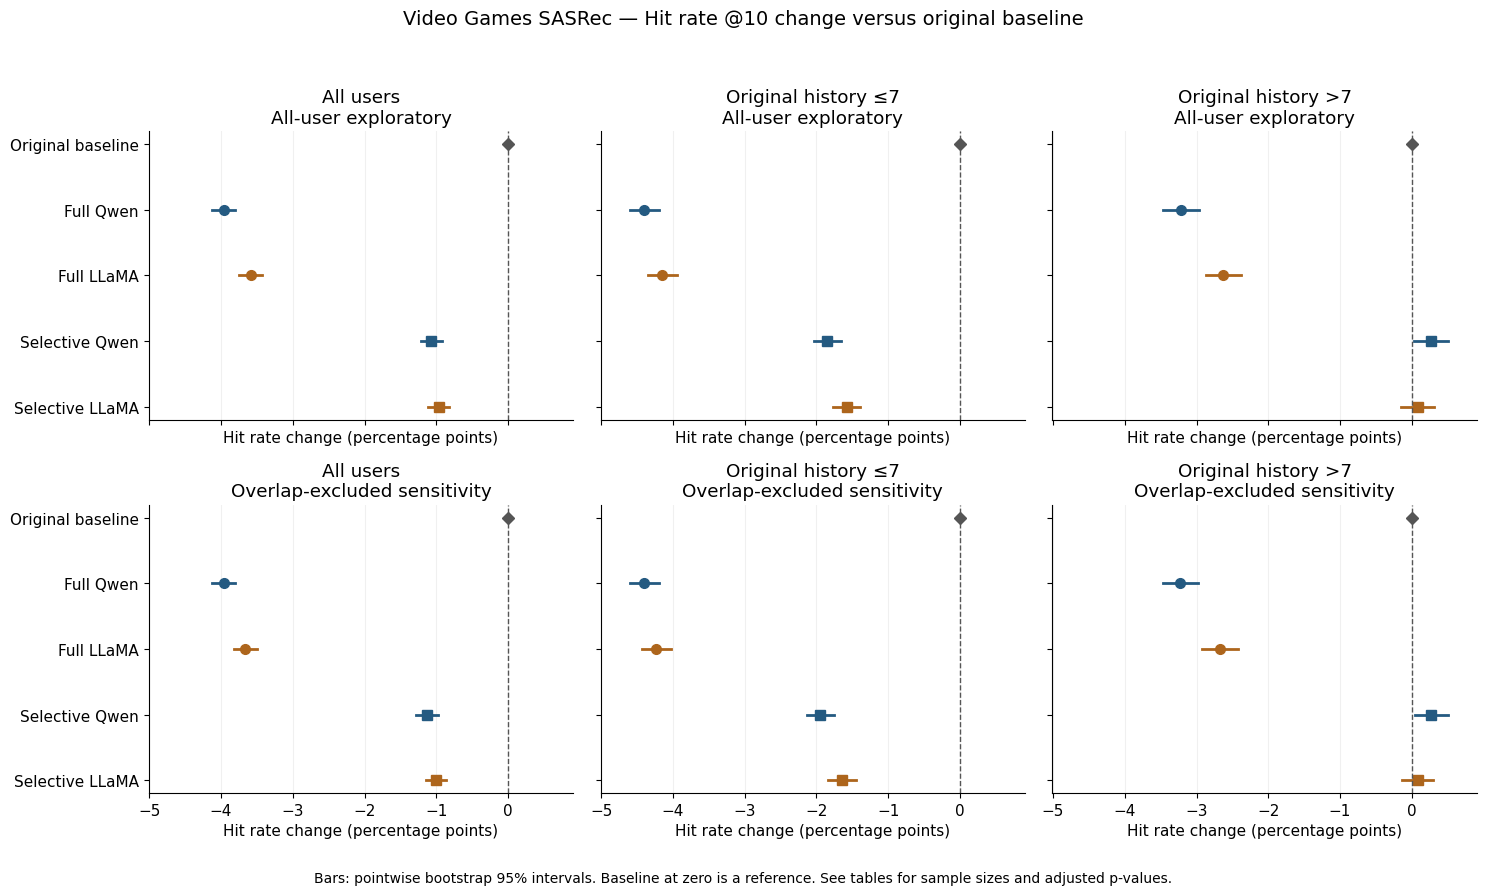

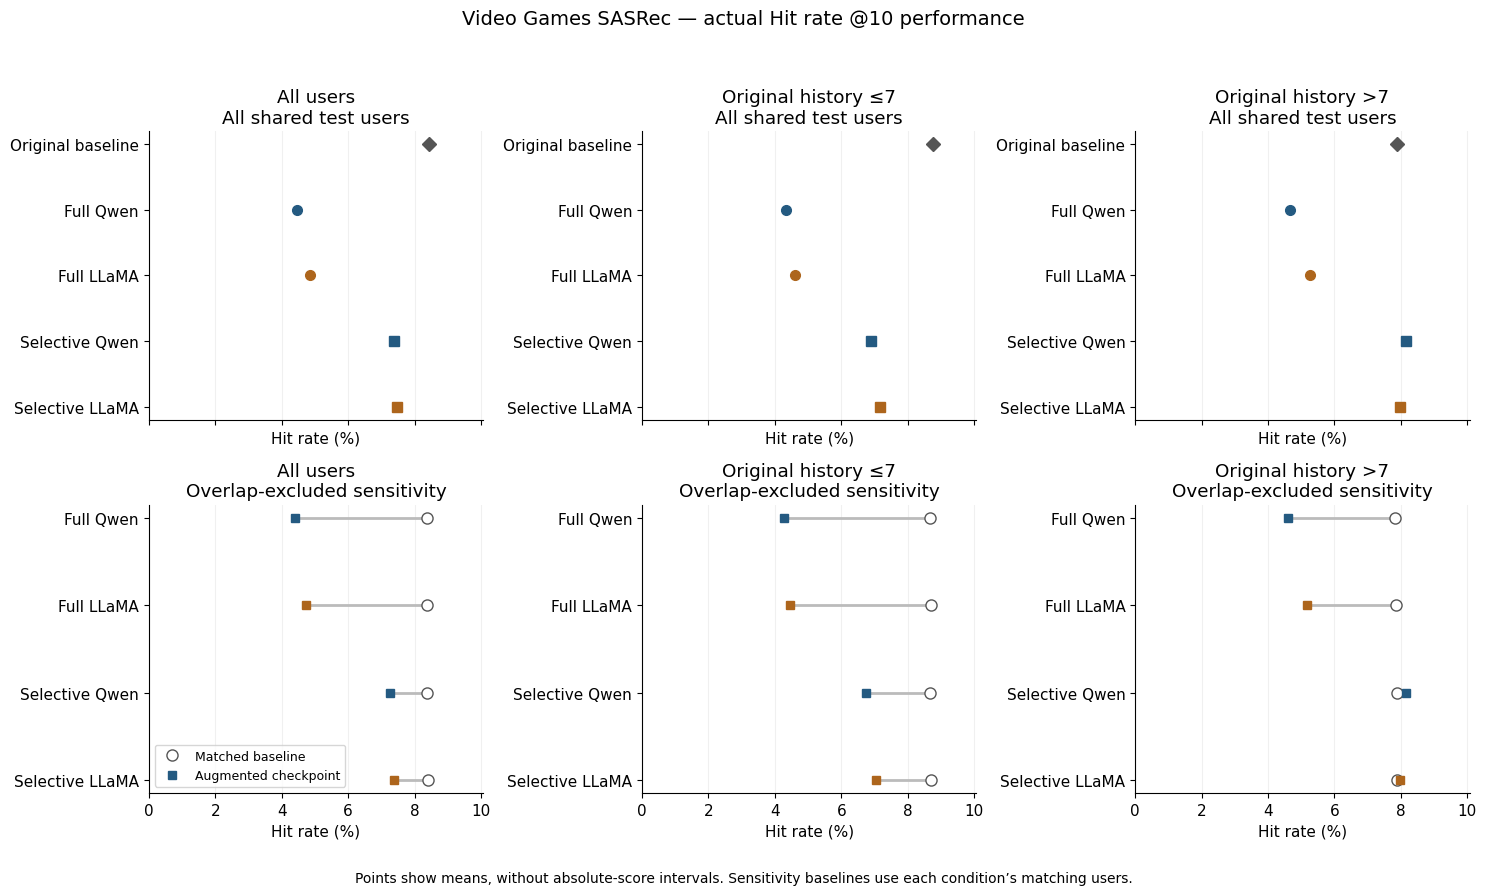

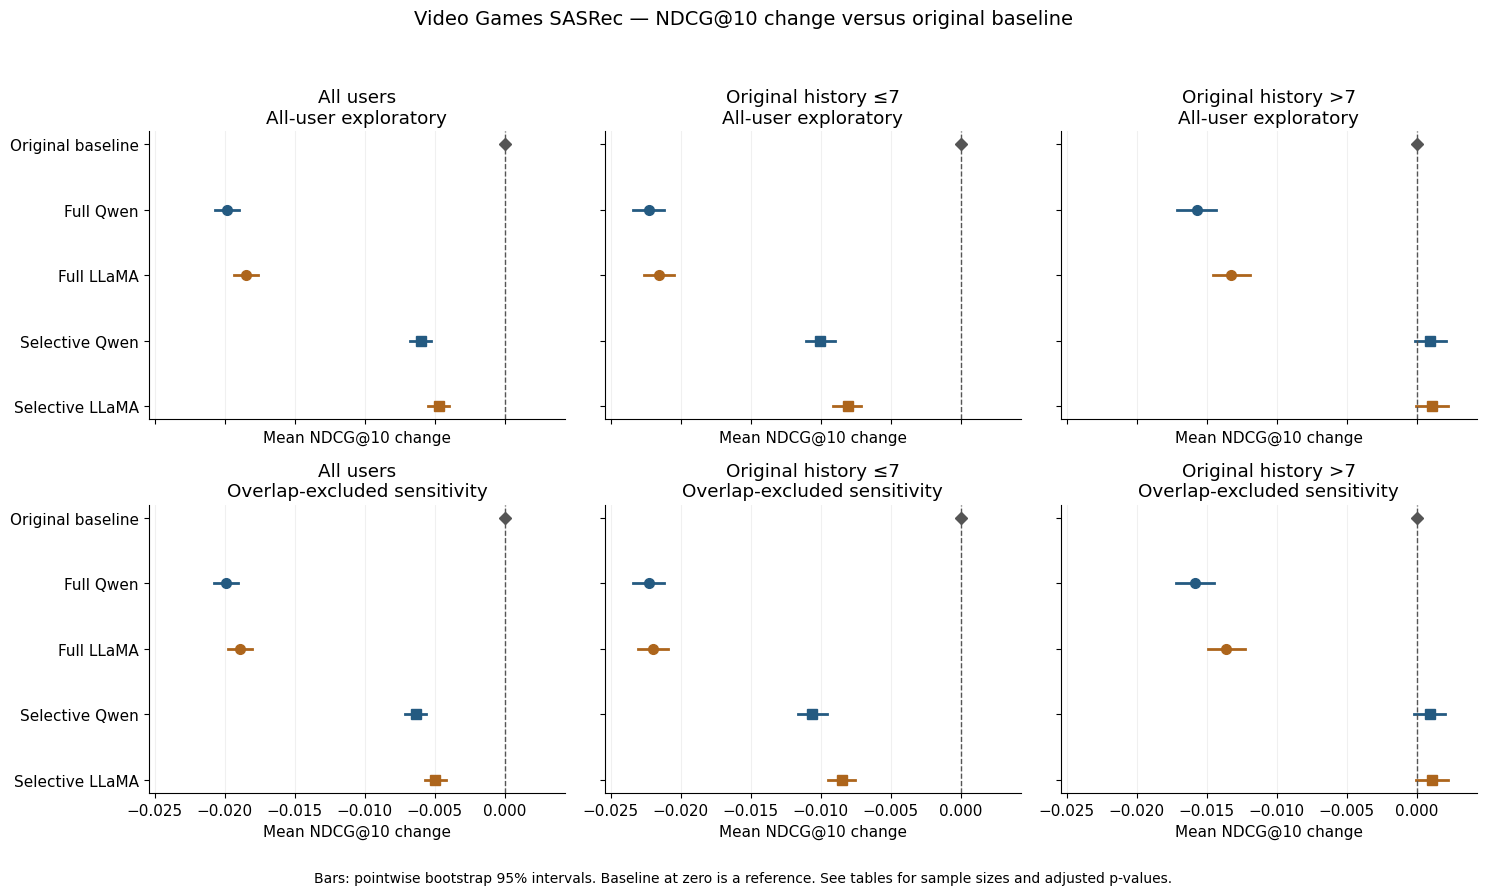

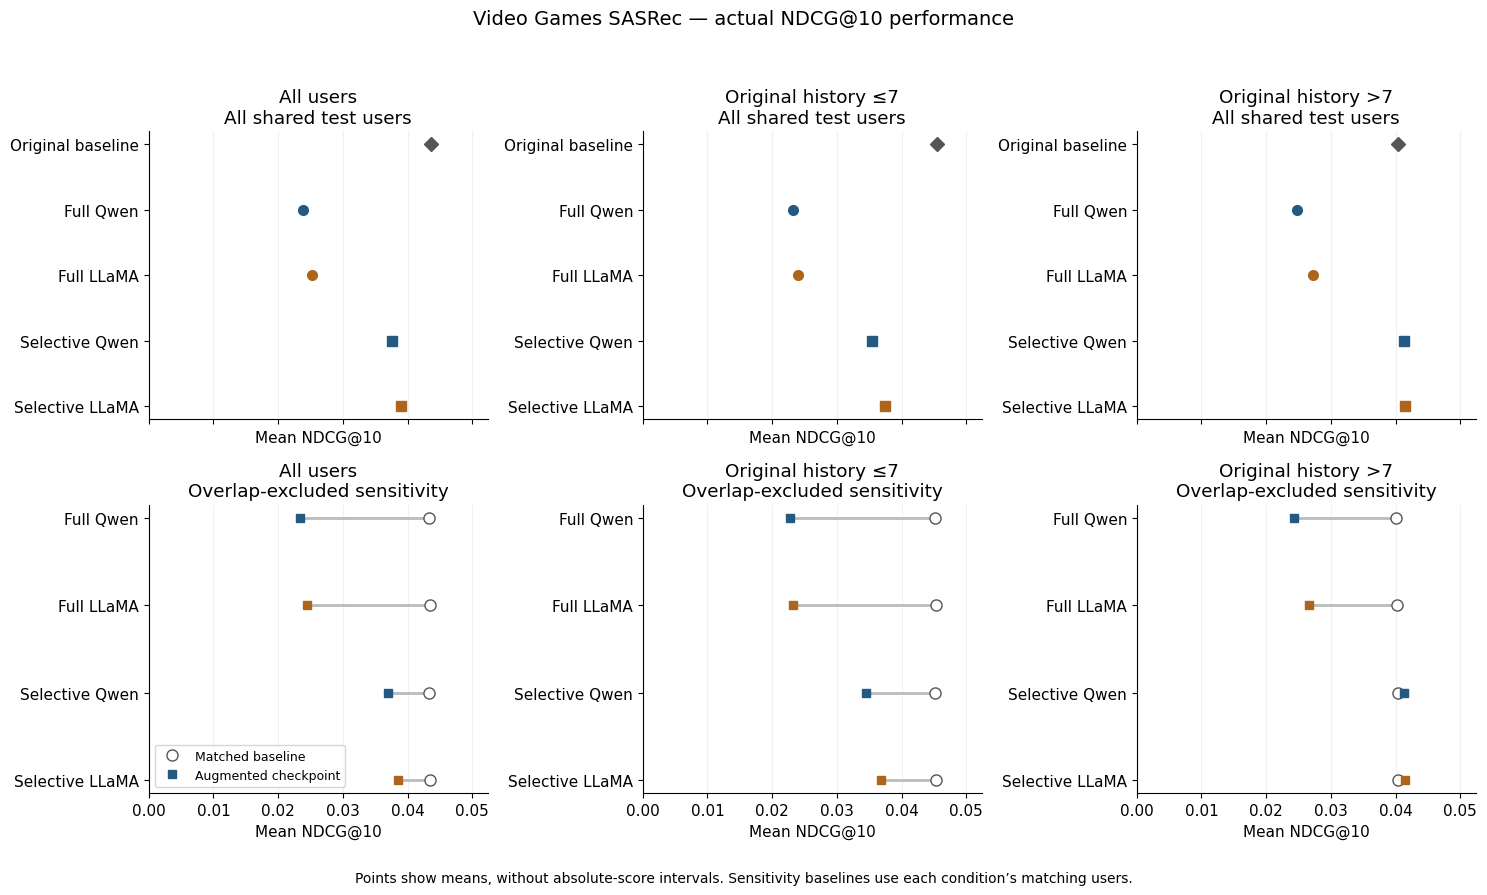

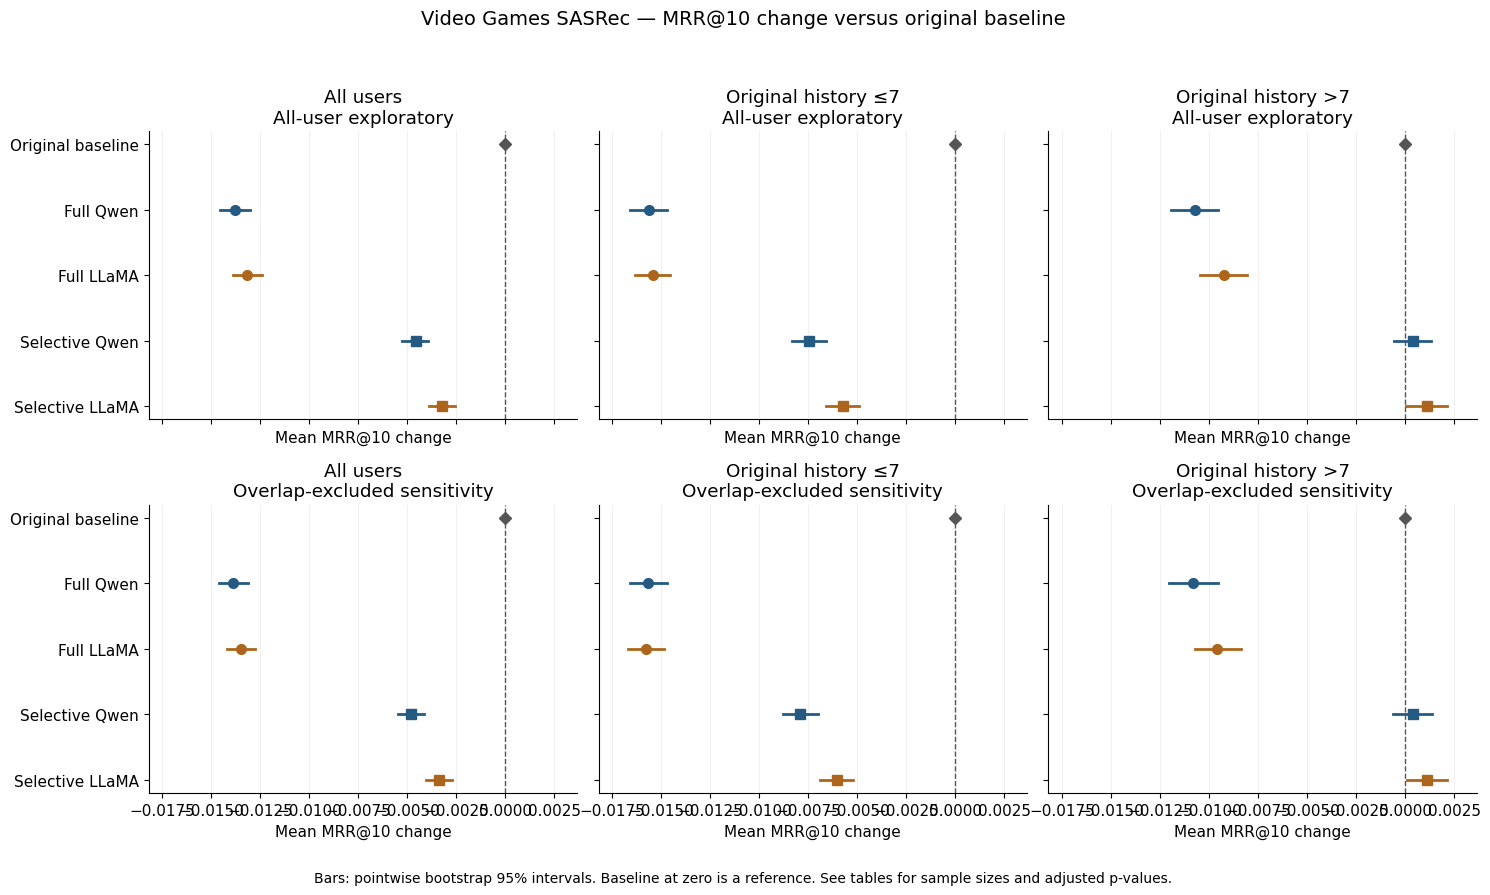

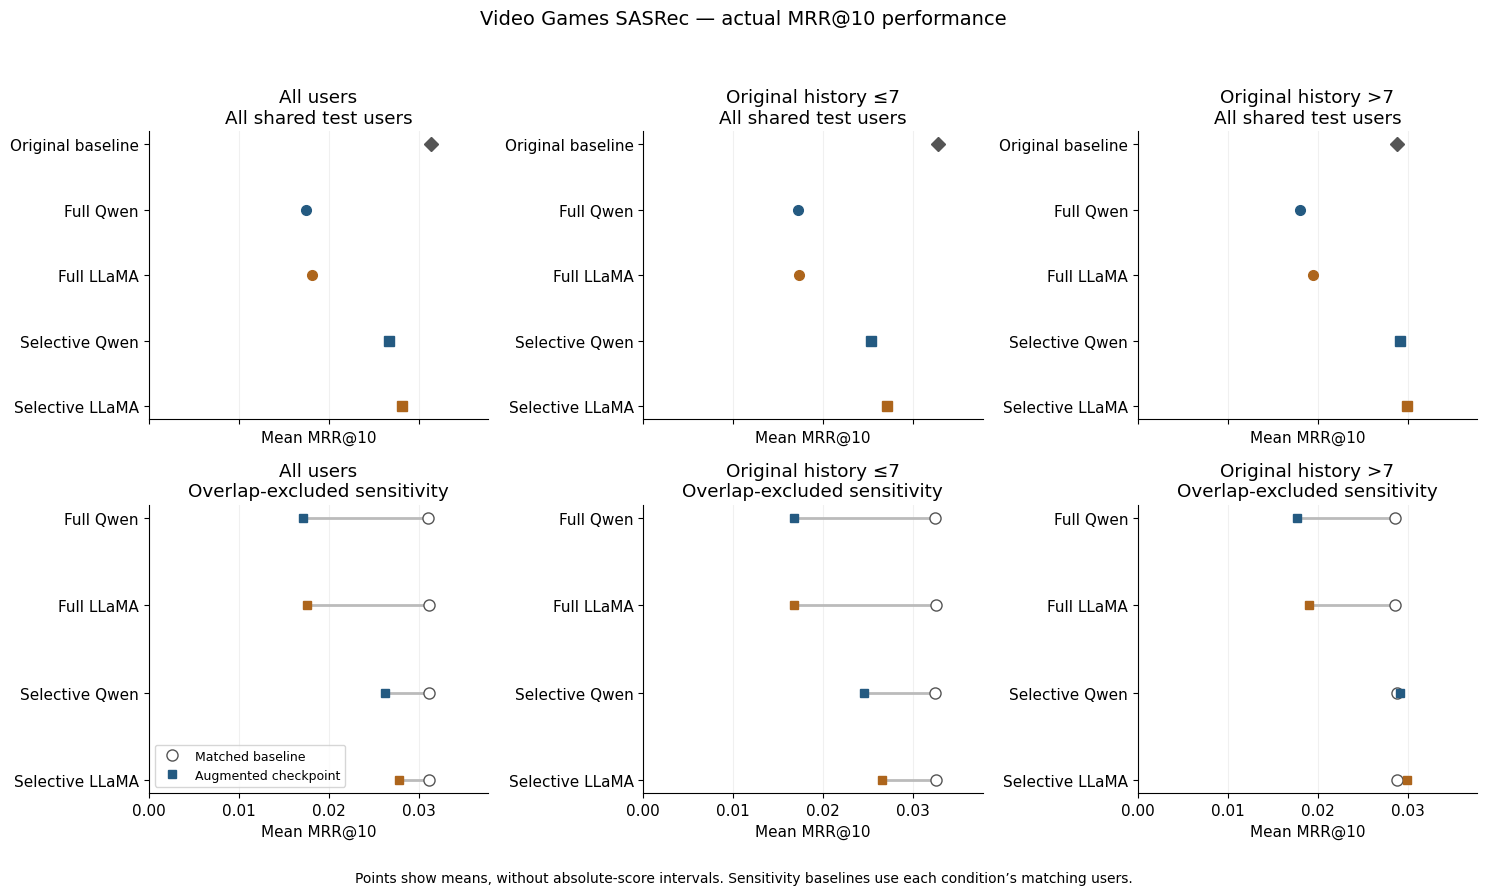

In [ ]:
COLORS = {'full_qwen': '#245A81', 'selective_qwen': '#245A81', 'full_llama': '#AD651C', 'selective_llama': '#AD651C'}
BASELINE_COLOR = '#555555'

def save_and_show(fig, filename):
    fig.savefig(RUN_DIR / 'figures' / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def plot_metric_results(result_table, absolute_table):
    for metric in DISPLAY_METRICS:
        selected = result_table.loc[result_table.metric.eq(metric)]
        scale = 100. if metric == 'hit@10' else 1.
        low, high = selected.ci95_low.min() * scale, selected.ci95_high.max() * scale
        span = max(high - low, .1 if metric == 'hit@10' else .001)
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
        for r, population in enumerate(POPULATIONS):
            for axis, group in zip(axes[r], GROUPS):
                rows = selected.loc[selected.population.eq(population) & selected.group.eq(group)].set_index('condition')
                axis.plot(0, 0, marker='D', color=BASELINE_COLOR, markersize=6)
                for y, condition in enumerate(CONDITIONS, start=1):
                    row = rows.loc[condition]
                    axis.plot([row.ci95_low * scale, row.ci95_high * scale], [y, y], color=COLORS[condition], linewidth=2)
                    axis.plot(row.delta * scale, y, marker='o' if condition.startswith('full') else 's', color=COLORS[condition], markersize=7)
                axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
                axis.set_xlim(min(low, 0) - .08 * span, max(high, 0) + .08 * span)
                axis.set_yticks(range(len(CONDITIONS) + 1), ['Original baseline'] + [LABELS[c] for c in CONDITIONS])
                axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
                axis.grid(axis='x', alpha=.18)
                axis.set_xlabel('Hit rate change (percentage points)' if metric == 'hit@10' else f'Mean {METRIC_TITLES[metric]} change')
        axes[0, 0].invert_yaxis()
        fig.suptitle('Video Games SASRec — ' + METRIC_TITLES[metric] + ' change versus original baseline', fontsize=14)
        fig.text(.5, .01, 'Bars: pointwise bootstrap 95% intervals. Baseline at zero is a reference. See tables for sample sizes and adjusted p-values.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_changes.png')

        # Main absolute values: five standalone rows. Sensitivity: matched pairs.
        max_value = max(absolute_table[metric].max(), selected[['baseline_mean', 'augmented_mean']].max().max()) * scale
        fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True)
        for axis, group in zip(axes[0], GROUPS):
            rows = absolute_table.loc[absolute_table.group.eq(group)].set_index('condition')
            for y, condition in enumerate(['baseline'] + CONDITIONS):
                axis.plot(rows.loc[condition, metric] * scale, y, marker='D' if condition == 'baseline' else ('o' if condition.startswith('full') else 's'),
                          color=BASELINE_COLOR if condition == 'baseline' else COLORS[condition], markersize=7)
            axis.set_yticks(range(len(CONDITIONS) + 1), [LABELS[c] for c in ['baseline'] + CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nAll shared test users')
        for axis, group in zip(axes[1], GROUPS):
            rows = selected.loc[selected.population.eq('overlap_excluded_sensitivity') & selected.group.eq(group)].set_index('condition')
            for y, condition in enumerate(CONDITIONS):
                row = rows.loc[condition]
                axis.plot([row.baseline_mean * scale, row.augmented_mean * scale], [y, y], color='#BBBBBB', linewidth=2)
                axis.plot(row.baseline_mean * scale, y, marker='o', markerfacecolor='white', markeredgecolor=BASELINE_COLOR, markersize=8,
                          linestyle='none', label='Matched baseline' if y == 0 else None)
                axis.plot(row.augmented_mean * scale, y, marker='s', color=COLORS[condition], markersize=6,
                          linestyle='none', label='Augmented checkpoint' if y == 0 else None)
            axis.set_yticks(range(len(CONDITIONS)), [LABELS[c] for c in CONDITIONS])
            axis.invert_yaxis()
            axis.set_title(GROUP_TITLES[group] + '\nOverlap-excluded sensitivity')
        axes[1, 0].legend(loc='best', fontsize=9)
        for axis in axes.flat:
            axis.set_xlim(0, max(max_value * 1.15, .1 if metric == 'hit@10' else .001))
            axis.set_xlabel('Hit rate (%)' if metric == 'hit@10' else 'Mean ' + METRIC_TITLES[metric])
            axis.grid(axis='x', alpha=.18)
        fig.suptitle('Video Games SASRec — actual ' + METRIC_TITLES[metric] + ' performance', fontsize=14)
        fig.text(.5, .01, 'Points show means, without absolute-score intervals. Sensitivity baselines use each condition’s matching users.', ha='center', fontsize=10)
        fig.tight_layout(rect=[0, .04, 1, .95])
        save_and_show(fig, f'{metric.replace("@", "_")}_absolute_scores.png')

plot_metric_results(table, overview)

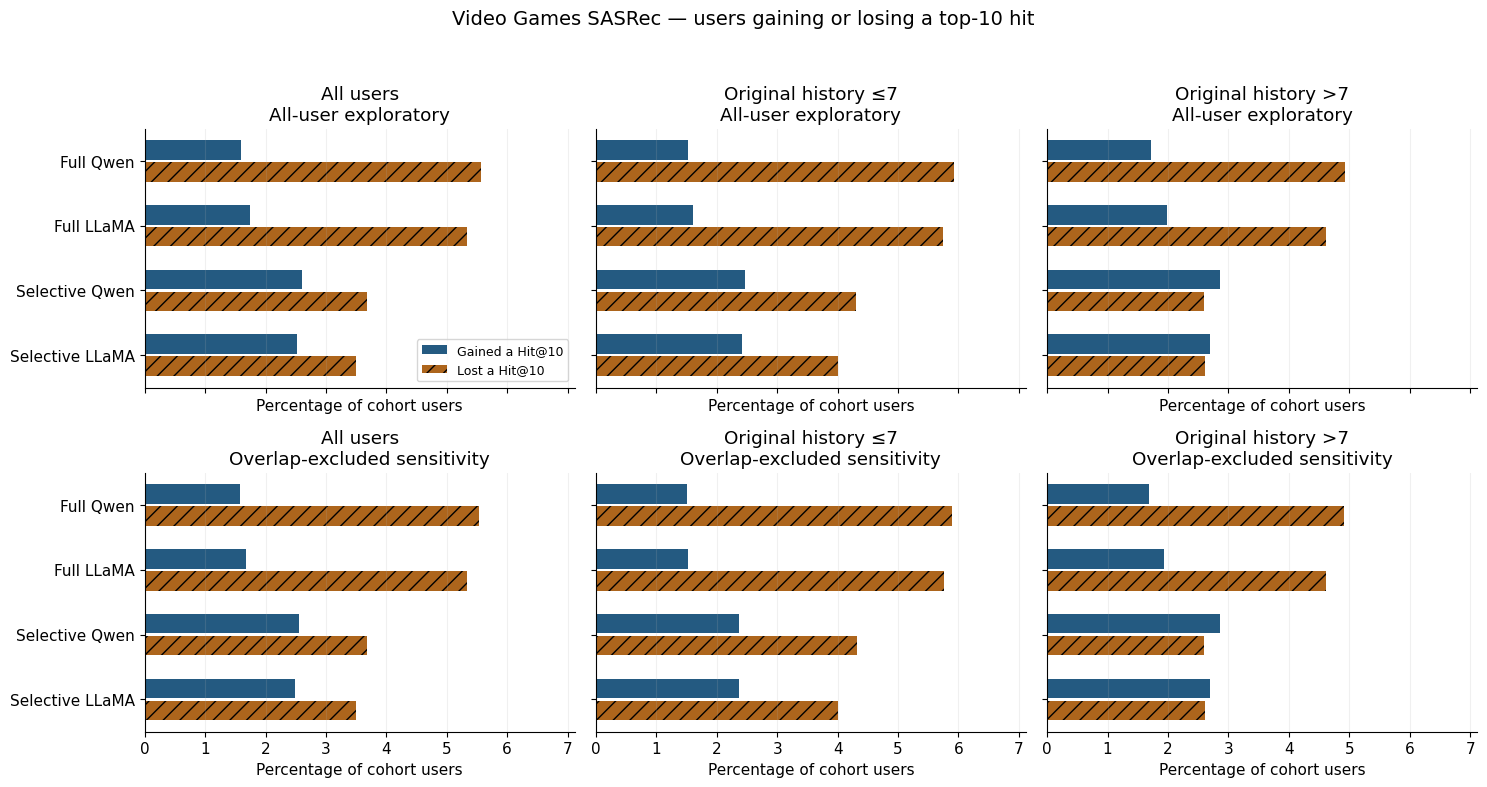

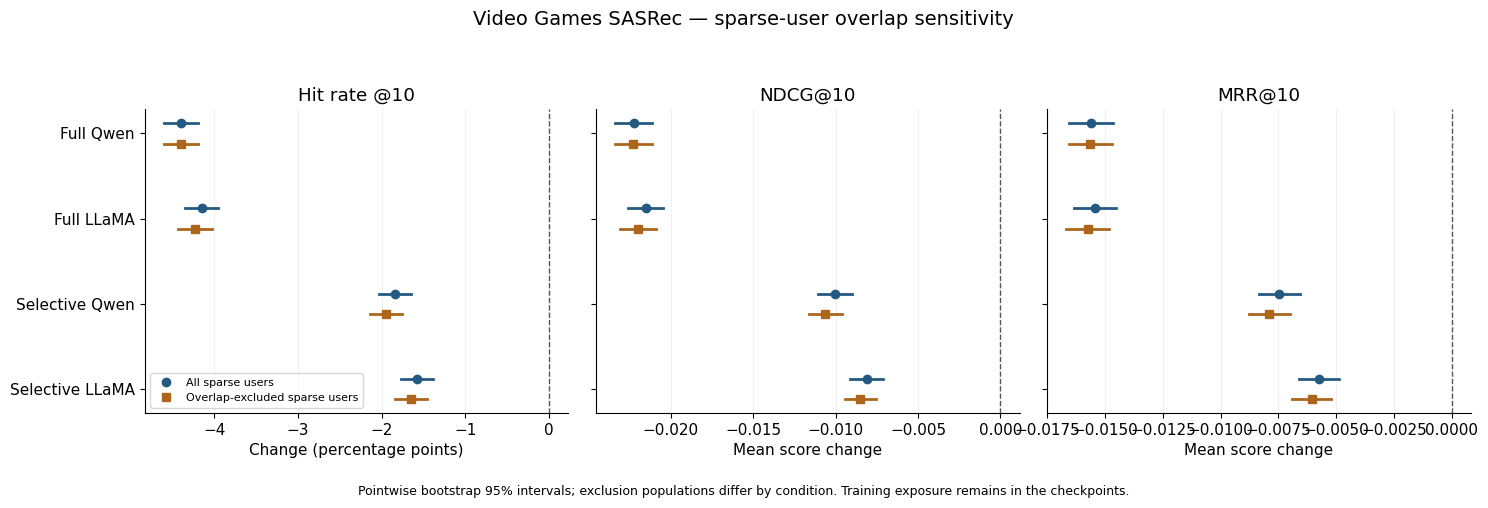

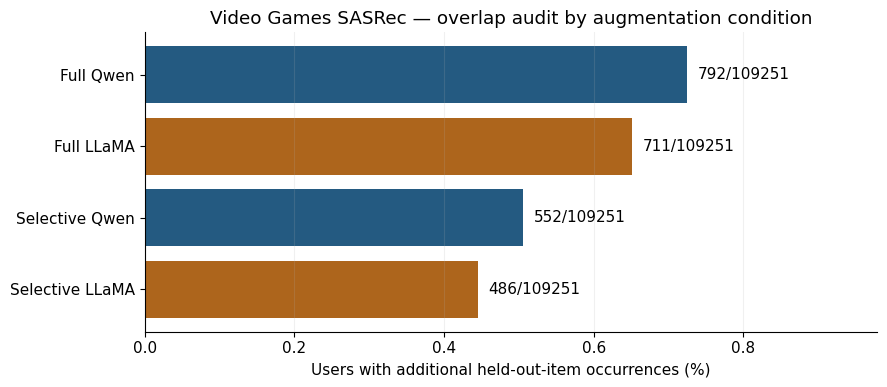

In [ ]:
# User-level Hit gains and losses.
limit = max(transitions[['gained_hit_pct', 'lost_hit_pct']].max().max() * 1.2, .1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for r, population in enumerate(POPULATIONS):
    for axis, group in zip(axes[r], GROUPS):
        rows = transitions.loc[transitions.population.eq(population) & transitions.group.eq(group)].set_index('condition').reindex(CONDITIONS)
        y = np.arange(len(CONDITIONS))
        axis.barh(y - .17, rows.gained_hit_pct, height=.3, color='#245A81', label='Gained a Hit@10')
        axis.barh(y + .17, rows.lost_hit_pct, height=.3, color='#AD651C', hatch='//', label='Lost a Hit@10')
        axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
        axis.set_title(GROUP_TITLES[group] + '\n' + ('All-user exploratory' if r == 0 else 'Overlap-excluded sensitivity'))
        axis.set_xlim(0, limit)
        axis.set_xlabel('Percentage of cohort users')
        axis.grid(axis='x', alpha=.18)
axes[0, 0].invert_yaxis()
axes[0, 0].legend(loc='best', fontsize=9)
fig.suptitle('Video Games SASRec — users gaining or losing a top-10 hit', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .95])
save_and_show(fig, 'hit_gains_and_losses.png')

# Side-by-side sensitivity estimates for sparse users, all three metrics.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for axis, metric in zip(axes, DISPLAY_METRICS):
    scale = 100. if metric == 'hit@10' else 1.
    for j, population in enumerate(POPULATIONS):
        rows = table.loc[table.metric.eq(metric) & table.group.eq('sparse') & table.population.eq(population)].set_index('condition')
        for y, condition in enumerate(CONDITIONS):
            row = rows.loc[condition]
            yy = y + (-.12 if j == 0 else .12)
            color = '#245A81' if j == 0 else '#AD651C'
            axis.plot([row.ci95_low * scale, row.ci95_high * scale], [yy, yy], color=color, linewidth=2)
            axis.plot(row.delta * scale, yy, marker='o' if j == 0 else 's', color=color, markersize=6,
                      linestyle='none', label=('All sparse users' if j == 0 else 'Overlap-excluded sparse users') if y == 0 else None)
    axis.axvline(0, color=BASELINE_COLOR, linestyle='--', linewidth=1)
    axis.set_title(METRIC_TITLES[metric])
    axis.set_xlabel('Change (percentage points)' if metric == 'hit@10' else 'Mean score change')
    axis.set_yticks(range(len(CONDITIONS)), [LABELS[c] for c in CONDITIONS])
    axis.grid(axis='x', alpha=.18)
axes[0].invert_yaxis()
axes[0].legend(loc='best', fontsize=8)
fig.suptitle('Video Games SASRec — sparse-user overlap sensitivity', fontsize=14)
fig.text(.5, .01, 'Pointwise bootstrap 95% intervals; exclusion populations differ by condition. Training exposure remains in the checkpoints.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, .05, 1, .93])
save_and_show(fig, 'sparse_overlap_sensitivity_all_metrics.png')

fig, axis = plt.subplots(figsize=(9, 4))
ordered_audits = audits.set_index('condition').reindex(CONDITIONS)
y = np.arange(len(CONDITIONS))
axis.barh(y, ordered_audits.overlap_pct, color=[COLORS[c] for c in CONDITIONS])
axis.set_yticks(y, [LABELS[c] for c in CONDITIONS])
axis.invert_yaxis()
axis.set_xlabel('Users with additional held-out-item occurrences (%)')
axis.set_title('Video Games SASRec — overlap audit by augmentation condition')
maximum = max(float(ordered_audits.overlap_pct.max()), .1)
axis.set_xlim(0, maximum * 1.35)
for yy, row in enumerate(ordered_audits.itertuples()):
    axis.text(row.overlap_pct + .02 * maximum, yy, f'{row.any_overlap_users}/{row.users}', va='center')
axis.grid(axis='x', alpha=.18)
fig.tight_layout()
save_and_show(fig, 'holdout_overlap_audit.png')

In [ ]:
environment = {p: package_metadata.version(p) for p in ['torch', 'recbole', 'numpy', 'pandas', 'scipy']}
manifest = {'scope': 'Video Games SASRec verified available conditions', 'unavailable_conditions': UNAVAILABLE_CONDITIONS,
            'evaluation_protocol': 'Common real-item catalogue and shared users; separate native historical reproduction',
            'common_users': len(COMMON_USERS), 'common_items': len(COMMON_ITEMS), 'threshold': THRESHOLD,
            'k': K, 'seed': SEED, 'bootstrap_resamples': BOOTSTRAP_RESAMPLES,
            'difference_tests_per_population': 36, 'observed_difference_tests_per_population': len(CONDITIONS) * 3 * len(METRICS),
            'policy_tests_per_population': 18, 'hit_mcnemar_tests_per_population': 12,
            'derived_metrics': {'recall@10': 'hit@10', 'precision@10': 'hit@10 / 10'},
            'no_harm_margins': NO_HARM_MARGINS, 'margin_justifications': MARGIN_JUSTIFICATIONS,
            'environment': environment, 'inputs': provenance,
            'limitations': ['Checkpoint-conditional inference; no repeated training seeds',
                           'Different training batch sizes', 'Synthetic holdout-item overlaps',
                           'Sensitivity exclusions do not undo model training exposure',
                           'Pointwise intervals; adjusted p-values govern multiple-test decisions']}
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=str))
summary_lines = ['Video Games SASRec full/selective augmentation comparisons',
                 'Delta = augmented minus baseline. All conclusions refer to these checkpoints.',
                 'Holm correction: 36 planned difference tests per population.', '']
for row in table.to_dict('records'):
    p = row['p_holm']
    conclusion = ('statistically detected increase' if row['delta'] > 0 else 'statistically detected decrease') if pd.notna(p) and p < .05 else 'difference not established under Holm correction'
    summary_lines.append(f"{row['condition']} | {row['population']} | {row['group']} | {row['metric']} | n={row['users']} | delta={row['delta']:.6f} | {conclusion}")
summary_lines += ['', 'Nonsignificance does not establish equivalence or no meaningful harm.',
                  'Full longer-history users received augmentation; selective longer-history users did not.',
                  'Overlap-excluded sensitivity is not a contamination-free retraining experiment.']
(RUN_DIR / 'analysis/interpretation.txt').write_text('\n'.join(summary_lines))
print('\n'.join(summary_lines))
print('\nAll outputs:', RUN_DIR)

Video Games SASRec full/selective augmentation comparisons
Delta = augmented minus baseline. All conclusions refer to these checkpoints.
Holm correction: 36 planned difference tests per population.

full_qwen | all_users_exploratory | all | ndcg@10 | n=109251 | delta=-0.019852 | statistically detected decrease
full_qwen | all_users_exploratory | all | hit@10 | n=109251 | delta=-0.039643 | statistically detected decrease
full_qwen | all_users_exploratory | all | mrr@10 | n=109251 | delta=-0.013807 | statistically detected decrease
full_qwen | all_users_exploratory | sparse | ndcg@10 | n=69069 | delta=-0.022257 | statistically detected decrease
full_qwen | all_users_exploratory | sparse | hit@10 | n=69069 | delta=-0.044014 | statistically detected decrease
full_qwen | all_users_exploratory | sparse | mrr@10 | n=69069 | delta=-0.015608 | statistically detected decrease
full_qwen | all_users_exploratory | longer_history | ndcg@10 | n=40182 | delta=-0.015719 | statistically detected decreas

## Next steps
Share `analysis/absolute_performance.csv`, `analysis/group_results.csv`, `analysis/hit_transitions.csv`, `analysis/full_vs_selective.csv`, `analysis/cohort_effect_contrasts.csv` and `preparation/augmentation_audit.csv` for interpretation. Keep the new `run_manifest.json` and checkpoint-config audit with your results. To reuse this for another model/dataset, explicitly update checkpoint names, recorded results, expected augmentation policy and cohort rules; this notebook is restricted to the named Video Games recommender and does not silently extend to other models or Video Games.

For a controlled augmentation-only claim, use matched training settings and remove synthetic holdout-item overlaps before training. Existing-checkpoint sensitivity analyses cannot replace that experiment. Agree a meaningful no-harm margin with your supervisor before using the optional margin cell.